In [2]:
import pandas as pd

train = pd.read_csv("student_train.csv")
test = pd.read_csv("student_test.csv")
external = pd.read_csv("optional_external_data.csv")

print("TRAIN")
print(train.shape)
print(train.columns.tolist())

print("\nTEST")
print(test.shape)
print(test.columns.tolist())

print("\nEXTERNAL")
print(external.shape)
print(external.columns.tolist())

TRAIN
(43656, 2)
['time_idx', 'value']

TEST
(168, 2)
['time_idx', 'value']

EXTERNAL
(43824, 11)
['time_idx', 'feature_A', 'feature_B', 'feature_C', 'feature_D', 'feature_E', 'feature_F', 'feature_G', 'feature_H', 'feature_I', 'feature_J']


In [3]:
print("=== TRAIN INFO ===")
print(train.info())

print("\n=== TRAIN MISSING VALUES ===")
print(train.isna().sum())

print("\n=== TEST MISSING VALUES ===")
print(test.isna().sum())

print("\n=== EXTERNAL MISSING VALUES ===")
print(external.isna().sum())

print("\n=== TRAIN FIRST 5 ROWS ===")
print(train.head())

print("\n=== TRAIN LAST 5 ROWS ===")
print(train.tail())

print("\n=== TEST FIRST 5 ROWS ===")
print(test.head())

print("\n=== TEST LAST 5 ROWS ===")
print(test.tail())

=== TRAIN INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 43656 entries, 0 to 43655
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   time_idx  43656 non-null  int64
 1   value     43656 non-null  int64
dtypes: int64(2)
memory usage: 682.3 KB
None

=== TRAIN MISSING VALUES ===
time_idx    0
value       0
dtype: int64

=== TEST MISSING VALUES ===
time_idx      0
value       168
dtype: int64

=== EXTERNAL MISSING VALUES ===
time_idx     0
feature_A    0
feature_B    0
feature_C    0
feature_D    0
feature_E    0
feature_F    0
feature_G    0
feature_H    0
feature_I    0
feature_J    0
dtype: int64

=== TRAIN FIRST 5 ROWS ===
   time_idx  value
0         1    129
1         2    129
2         3    129
3         4    129
4         5    129

=== TRAIN LAST 5 ROWS ===
       time_idx  value
43651     43652     20
43652     43653     23
43653     43654     16
43654     43655     17
43655     43656     18

=== TEST FIRST 5 ROWS ===
 

In [4]:
print("=== TARGET STATISTICS ===")
print(train["value"].describe())

print("\n=== UNIQUE VALUES ===")
print("Number of unique values:", train["value"].nunique())

print("\n=== MIN / MAX ===")
print("Minimum:", train["value"].min())
print("Maximum:", train["value"].max())

print("\n=== SELECTED QUANTILES ===")
print(train["value"].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

print("\n=== FIRST/LAST WINDOW MEANS ===")
print("First 168 mean:", train["value"].iloc[:168].mean())
print("Last 168 mean:", train["value"].iloc[-168:].mean())

print("\n=== FIRST/LAST WINDOW MEDIANS ===")
print("First 168 median:", train["value"].iloc[:168].median())
print("Last 168 median:", train["value"].iloc[-168:].median())

=== TARGET STATISTICS ===
count    43656.000000
mean        98.173539
std         90.834754
min          0.000000
25%         30.000000
50%         73.000000
75%        136.000000
max        994.000000
Name: value, dtype: float64

=== UNIQUE VALUES ===
Number of unique values: 584

=== MIN / MAX ===
Minimum: 0
Maximum: 994

=== SELECTED QUANTILES ===
0.01      6.0
0.05     10.0
0.25     30.0
0.50     73.0
0.75    136.0
0.95    282.0
0.99    418.0
Name: value, dtype: float64

=== FIRST/LAST WINDOW MEANS ===
First 168 mean: 79.0
Last 168 mean: 69.6547619047619

=== FIRST/LAST WINDOW MEDIANS ===
First 168 median: 65.5
Last 168 median: 22.5


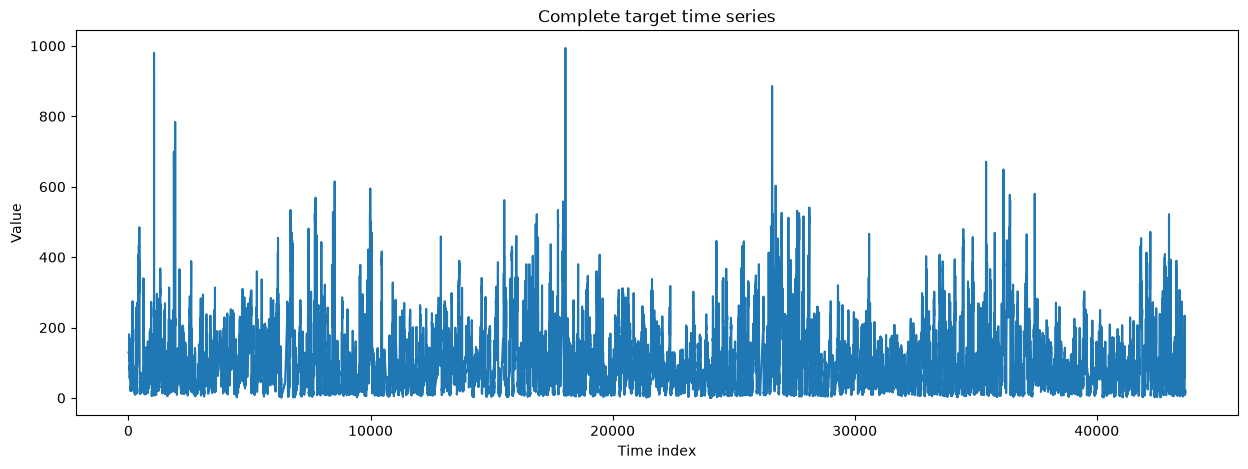

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(train["time_idx"], train["value"])
plt.xlabel("Time index")
plt.ylabel("Value")
plt.title("Complete target time series")
plt.show()

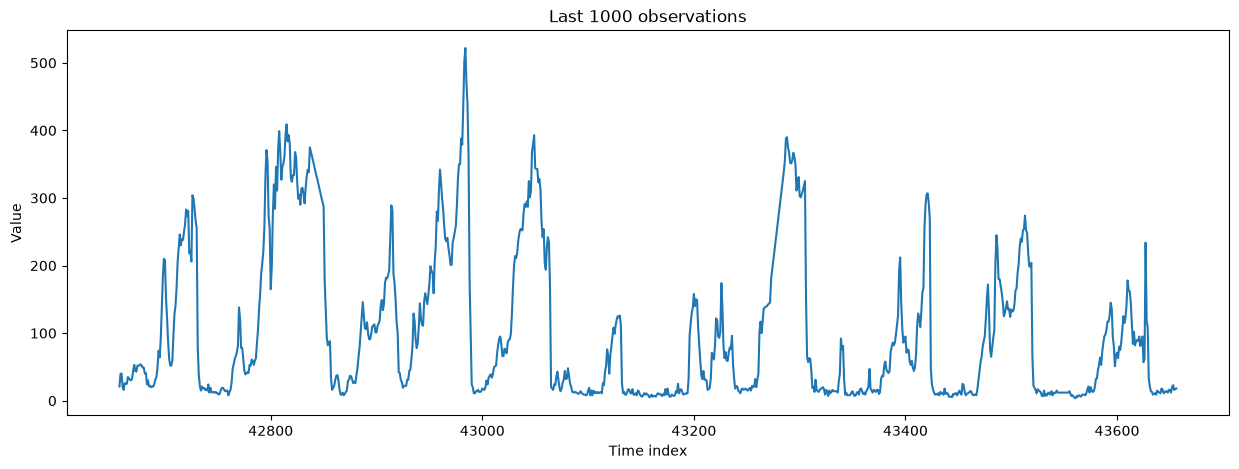

In [7]:
plt.figure(figsize=(15, 5))
plt.plot(train["time_idx"].iloc[-1000:], train["value"].iloc[-1000:])
plt.xlabel("Time index")
plt.ylabel("Value")
plt.title("Last 1000 observations")
plt.show()

In [5]:
import numpy as np
import pandas as pd

y = train["value"].to_numpy()

print("=== OVERALL ===")
print("Length:", len(y))
print("Mean:", y.mean())
print("Std:", y.std())
print("Min:", y.min())
print("Max:", y.max())

print("\n=== 168-STEP BLOCKS ===")

block_size = 168
num_blocks = len(y) // block_size

for i in range(num_blocks):
    block = y[i * block_size:(i + 1) * block_size]

    print(
        f"Block {i+1:3d} | "
        f"range {i*168+1:5d}-{(i+1)*168:5d} | "
        f"mean={block.mean():8.2f} | "
        f"std={block.std():8.2f} | "
        f"min={block.min():4d} | "
        f"max={block.max():4d}"
    )

=== OVERALL ===
Length: 43656
Mean: 98.17353857430822
Std: 90.83371369641951
Min: 0
Max: 994

=== 168-STEP BLOCKS ===
Block   1 | range     1-  168 | mean=   79.00 | std=   47.91 | min=  20 | max= 198
Block   2 | range   169-  336 | mean=   70.95 | std=   63.58 | min=   9 | max= 275
Block   3 | range   337-  504 | mean=  163.66 | std=  128.69 | min=  11 | max= 485
Block   4 | range   505-  672 | mean=   62.95 | std=   63.14 | min=  12 | max= 340
Block   5 | range   673-  840 | mean=   53.41 | std=   31.67 | min=  10 | max= 161
Block   6 | range   841- 1008 | mean=   89.40 | std=   70.49 | min=   6 | max= 273
Block   7 | range  1009- 1176 | mean=   71.96 | std=  119.29 | min=   7 | max= 980
Block   8 | range  1177- 1344 | mean=  160.79 | std=   76.45 | min=  20 | max= 368
Block   9 | range  1345- 1512 | mean=  103.12 | std=   62.20 | min=  13 | max= 269
Block  10 | range  1513- 1680 | mean=   66.60 | std=   56.30 | min=   5 | max= 248
Block  11 | range  1681- 1848 | mean=   74.63 | std=

In [6]:
print("\n=== AUTOCORRELATION ===")

y_series = train["value"]

for lag in [1, 2, 3, 4, 5, 6, 7, 12, 24, 48, 72, 96, 120, 144, 168, 192, 336, 504, 672]:
    print(f"Lag {lag:3d}: {y_series.autocorr(lag):.4f}")


=== AUTOCORRELATION ===
Lag   1: 0.9661
Lag   2: 0.9200
Lag   3: 0.8743
Lag   4: 0.8312
Lag   5: 0.7894
Lag   6: 0.7493
Lag   7: 0.7120
Lag  12: 0.5698
Lag  24: 0.4015
Lag  48: 0.1579
Lag  72: 0.0766
Lag  96: 0.0194
Lag 120: 0.0400
Lag 144: 0.0382
Lag 168: 0.0281
Lag 192: 0.0557
Lag 336: 0.0480
Lag 504: 0.0291
Lag 672: 0.0365


In [7]:
import numpy as np

y = train["value"].to_numpy(dtype=float)

# Remove the mean before looking for periodic structure
y_centered = y - y.mean()

# FFT
fft_values = np.fft.rfft(y_centered)
power = np.abs(fft_values) ** 2

# Corresponding frequencies
freqs = np.fft.rfftfreq(len(y_centered), d=1)

# Ignore frequency 0
power[0] = 0

# Find strongest frequencies
top_indices = np.argsort(power)[-20:][::-1]

print("=== STRONGEST FFT FREQUENCIES ===")

for idx in top_indices:
    frequency = freqs[idx]

    if frequency > 0:
        period = 1 / frequency
        print(
            f"Frequency={frequency:.6f} | "
            f"Period={period:.2f} steps | "
            f"Power={power[idx]:.2e}"
        )

=== STRONGEST FFT FREQUENCIES ===
Frequency=0.000092 | Period=10914.00 steps | Power=9.50e+10
Frequency=0.000344 | Period=2910.40 steps | Power=8.23e+10
Frequency=0.000115 | Period=8731.20 steps | Power=7.58e+10
Frequency=0.003711 | Period=269.48 steps | Power=7.29e+10
Frequency=0.041667 | Period=24.00 steps | Power=6.97e+10
Frequency=0.000137 | Period=7276.00 steps | Power=6.75e+10
Frequency=0.002588 | Period=386.34 steps | Power=5.64e+10
Frequency=0.005452 | Period=183.43 steps | Power=5.53e+10
Frequency=0.005337 | Period=187.36 steps | Power=4.74e+10
Frequency=0.001878 | Period=532.39 steps | Power=4.71e+10
Frequency=0.004810 | Period=207.89 steps | Power=4.66e+10
Frequency=0.002955 | Period=338.42 steps | Power=4.53e+10
Frequency=0.002657 | Period=376.34 steps | Power=4.44e+10
Frequency=0.002543 | Period=393.30 steps | Power=4.29e+10
Frequency=0.001191 | Period=839.54 steps | Power=4.05e+10
Frequency=0.004077 | Period=245.26 steps | Power=4.05e+10
Frequency=0.003459 | Period=289.11

In [8]:
print("=== EXTERNAL DATA SUMMARY ===")

print("\nData types:")
print(external.dtypes)

print("\nUnique values:")
for col in external.columns:
    print(f"{col}: {external[col].nunique()}")

print("\nMin / Max:")
for col in external.columns[1:]:
    print(
        f"{col}: "
        f"min={external[col].min()}, "
        f"max={external[col].max()}"
    )

print("\nFirst 10 rows:")
print(external.head(10))

=== EXTERNAL DATA SUMMARY ===

Data types:
time_idx       int64
feature_A      int64
feature_B    float64
feature_C    float64
feature_D    float64
feature_E      int64
feature_F      int64
feature_G      int64
feature_H      int64
feature_I      int64
feature_J      int64
dtype: object

Unique values:
time_idx: 43824
feature_A: 69
feature_B: 64
feature_C: 60
feature_D: 2788
feature_E: 28
feature_F: 37
feature_G: 2
feature_H: 2
feature_I: 2
feature_J: 2

Min / Max:
feature_A: min=-40, max=28
feature_B: min=-19.0, max=42.0
feature_C: min=991.0, max=1046.0
feature_D: min=0.45, max=585.6
feature_E: min=0, max=27
feature_F: min=0, max=36
feature_G: min=0, max=1
feature_H: min=0, max=1
feature_I: min=0, max=1
feature_J: min=0, max=1

First 10 rows:
   time_idx  feature_A  feature_B  feature_C  feature_D  feature_E  feature_F  \
0         1        -21      -11.0     1021.0       1.79          0          0   
1         2        -21      -12.0     1020.0       4.92          0          0   
2  

In [9]:
import numpy as np
import pandas as pd

# Align target and external data on the observed training period
analysis_df = train.merge(
    external,
    on="time_idx",
    how="left"
)

features = [
    "feature_A",
    "feature_B",
    "feature_C",
    "feature_D",
    "feature_E",
    "feature_F",
    "feature_G",
    "feature_H",
    "feature_I",
    "feature_J"
]

print("=== PEARSON CORRELATION WITH TARGET ===")

correlations = analysis_df[["value"] + features].corr()["value"].drop("value")

print(correlations.sort_values(key=lambda x: x.abs(), ascending=False))


print("\n=== BINARY FEATURE COUNTS ===")

for col in ["feature_G", "feature_H", "feature_I", "feature_J"]:
    print(f"\n{col}:")
    print(analysis_df[col].value_counts().sort_index())


print("\n=== CHECK WHETHER BINARY FEATURES ARE MUTUALLY EXCLUSIVE ===")

binary_sum = analysis_df[
    ["feature_G", "feature_H", "feature_I", "feature_J"]
].sum(axis=1)

print(binary_sum.value_counts().sort_index())


print("\n=== TARGET STATISTICS BY BINARY STATE ===")

analysis_df["binary_state"] = (
    analysis_df["feature_G"].astype(str)
    + analysis_df["feature_H"].astype(str)
    + analysis_df["feature_I"].astype(str)
    + analysis_df["feature_J"].astype(str)
)

state_stats = (
    analysis_df
    .groupby("binary_state")["value"]
    .agg(["count", "mean", "median", "std", "max"])
    .sort_values("mean", ascending=False)
)

print(state_stats)

=== PEARSON CORRELATION WITH TARGET ===
feature_D   -0.244820
feature_H   -0.212161
feature_A    0.169473
feature_J    0.153856
feature_I    0.097418
feature_B   -0.088157
feature_F   -0.050278
feature_C   -0.048470
feature_G   -0.032758
feature_E    0.019428
Name: value, dtype: float64

=== BINARY FEATURE COUNTS ===

feature_G:
feature_G
0    38677
1     4979
Name: count, dtype: int64

feature_H:
feature_H
0    29593
1    14063
Name: count, dtype: int64

feature_I:
feature_I
0    28381
1    15275
Name: count, dtype: int64

feature_J:
feature_J
0    34317
1     9339
Name: count, dtype: int64

=== CHECK WHETHER BINARY FEATURES ARE MUTUALLY EXCLUSIVE ===
1    43656
Name: count, dtype: int64

=== TARGET STATISTICS BY BINARY STATE ===
              count        mean  median        std  max
binary_state                                           
0001           9339  124.963165    98.0  98.773846  980
0010          15275  110.235286    91.0  79.156550  845
1000           4979   89.880297    

In [10]:
import numpy as np
import pandas as pd

print("=== LAGGED CORRELATIONS ===")

y = train["value"].to_numpy(dtype=float)

lag_results = []

# Positive lag means:
# external[t-lag] is being compared with target[t]
lags = [0, 1, 2, 3, 6, 12, 24, 48, 72, 96, 120, 144, 168]

for feature in features:
    x = analysis_df[feature].to_numpy(dtype=float)

    for lag in lags:
        if lag == 0:
            x_lag = x
            y_lag = y
        else:
            x_lag = x[:-lag]
            y_lag = y[lag:]

        corr = np.corrcoef(x_lag, y_lag)[0, 1]

        lag_results.append({
            "feature": feature,
            "lag": lag,
            "correlation": corr
        })

lag_df = pd.DataFrame(lag_results)

# For each feature, show the lag producing
# the largest absolute correlation
best_lags = (
    lag_df
    .assign(abs_corr=lag_df["correlation"].abs())
    .sort_values(["feature", "abs_corr"], ascending=[True, False])
    .groupby("feature")
    .head(3)
)

for feature in features:
    print(f"\n{feature}:")
    print(
        best_lags[
            best_lags["feature"] == feature
        ][["lag", "correlation"]].to_string(index=False)
    )

=== LAGGED CORRELATIONS ===

feature_A:
 lag  correlation
   0     0.169473
   1     0.167159
   2     0.161525

feature_B:
 lag  correlation
 120    -0.121688
  96    -0.121661
  72    -0.119511

feature_C:
 lag  correlation
  48     0.138115
  72     0.135067
  96     0.128549

feature_D:
 lag  correlation
   0    -0.244820
   1    -0.244804
   2    -0.242847

feature_E:
 lag  correlation
 168     0.035736
 144     0.028345
 120     0.028178

feature_F:
 lag  correlation
  12    -0.064306
   6    -0.062814
   3    -0.059287

feature_G:
 lag  correlation
  12    -0.049101
   6    -0.044643
   3    -0.034761

feature_H:
 lag  correlation
   6    -0.304450
   3    -0.284338
   2    -0.266286

feature_I:
 lag  correlation
   6     0.191406
  12     0.168512
   3     0.148352

feature_J:
 lag  correlation
   3     0.178400
   2     0.177527
   1     0.167934


In [11]:
import numpy as np
import pandas as pd

y = train["value"].to_numpy(dtype=float)

H = 168

# Five chronological validation origins.
# Each origin leaves a complete 168-step future horizon.
origins = [
    len(y) - 5 * H,
    len(y) - 4 * H,
    len(y) - 3 * H,
    len(y) - 2 * H,
    len(y) - H
]

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))


def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))


def smape(y_true, y_pred):
    denominator = np.abs(y_true) + np.abs(y_pred)

    # Avoid division by zero
    mask = denominator != 0

    return 100 * np.mean(
        np.where(
            mask,
            2 * np.abs(y_pred - y_true) / denominator,
            0
        )
    )


results = []

for i, origin in enumerate(origins, start=1):

    # Last observed value before the validation horizon
    last_value = y[origin - 1]

    # Persistence forecast
    prediction = np.full(H, last_value)

    # Actual future values
    actual = y[origin:origin + H]

    results.append({
        "validation_block": i,
        "origin": origin,
        "last_value": last_value,
        "actual_mean": actual.mean(),
        "MAE": mae(actual, prediction),
        "RMSE": rmse(actual, prediction),
        "sMAPE": smape(actual, prediction)
    })


results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

print("\n=== AVERAGE ACROSS VALIDATION BLOCKS ===")

print(
    results_df[["MAE", "RMSE", "sMAPE"]]
    .mean()
)

 validation_block  origin  last_value  actual_mean        MAE       RMSE      sMAPE
                1   42816       384.0   178.369048 209.452381 240.057012  87.318838
                2   42984       522.0    94.422619 427.577381 442.454780 148.385827
                3   43152         8.0    99.023810  91.226190 146.575716 115.895798
                4   43320        18.0    54.773810  43.380952  76.841287  80.572706
                5   43488       180.0    69.654762 119.023810 131.412881 113.031757

=== AVERAGE ACROSS VALIDATION BLOCKS ===
MAE      178.132143
RMSE     207.468335
sMAPE    109.040985
dtype: float64


In [20]:
H = 168
PERIOD = 24

results = []

for i, origin in enumerate(origins, start=1):

    # History available before the validation origin
    history = y[:origin]

    # Last 24 observed values
    last_period = history[-PERIOD:]

    # Repeat the 24-step pattern for the entire forecast horizon
    prediction = np.tile(
        last_period,
        H // PERIOD
    )

    # Actual validation horizon
    actual = y[origin:origin + H]

    results.append({
        "validation_block": i,
        "origin": origin,
        "last_24_mean": last_period.mean(),
        "actual_mean": actual.mean(),
        "MAE": mae(actual, prediction),
        "RMSE": rmse(actual, prediction),
        "sMAPE": smape(actual, prediction)
    })


seasonal_results_df = pd.DataFrame(results)

print(seasonal_results_df.to_string(index=False))

print("\n=== AVERAGE ACROSS VALIDATION BLOCKS ===")

print(
    seasonal_results_df[["MAE", "RMSE", "sMAPE"]]
    .mean()
)

 validation_block  origin  last_24_mean  actual_mean        MAE       RMSE      sMAPE
                1   42816    319.875000   178.369049 165.517853 197.499985  78.953239
                2   42984    302.166656    94.422623 222.410721 249.826614 128.087158
                3   43152     25.375000    99.023811  87.220238 139.335312 106.105698
                4   43320    142.958328    54.773811 125.077377 172.691589 112.254288
                5   43488     97.708336    69.654762  86.327377 107.419540 107.768562

=== AVERAGE ACROSS VALIDATION BLOCKS ===
MAE      137.310715
RMSE     173.354614
sMAPE    106.633789
dtype: float32


In [21]:
# Step 1: Prepare the time-series arrays for Autoformer

import numpy as np

H = 168
L = 336

# Target values
y = train["value"].to_numpy(dtype=np.float32)

# External features
feature_cols = [
    "feature_A", "feature_B", "feature_C", "feature_D",
    "feature_E", "feature_F", "feature_G", "feature_H",
    "feature_I", "feature_J"
]

X_external = external[feature_cols].to_numpy(dtype=np.float32)

print("Target shape:", y.shape)
print("External shape:", X_external.shape)
print("Context length:", L)
print("Forecast horizon:", H)

# Check that the external data covers both the observed
# history and the hidden future horizon.
print("\nExternal data covers:")
print("time_idx:", external["time_idx"].iloc[0],
      "to", external["time_idx"].iloc[-1])

print("\nTest covers:")
print("time_idx:", test["time_idx"].iloc[0],
      "to", test["time_idx"].iloc[-1])

Target shape: (43656,)
External shape: (43824, 10)
Context length: 336
Forecast horizon: 168

External data covers:
time_idx: 1 to 43824

Test covers:
time_idx: 43657 to 43824


In [22]:
def make_forecast_window(y, external_features, origin, context_length=336, horizon=168):
    """
    Create one direct multi-step forecasting example.

    Parameters
    ----------
    y : numpy array
        Target time series.
    external_features : numpy array
        External features aligned with time_idx.
    origin : int
        First timestamp to forecast.
    context_length : int
        Number of historical target observations given to the model.
    horizon : int
        Number of future observations to predict.

    Returns
    -------
    history_y : (context_length,)
    history_external : (context_length, num_features)
    future_external : (horizon, num_features)
    target_y : (horizon,)
    """

    history_start = origin - context_length
    history_end = origin

    future_start = origin
    future_end = origin + horizon

    history_y = y[history_start:history_end]

    history_external = external_features[
        history_start:history_end
    ]

    future_external = external_features[
        future_start:future_end
    ]

    target_y = y[future_start:future_end]

    return (
        history_y,
        history_external,
        future_external,
        target_y
    )

In [23]:
origin = origins[0]

history_y, history_ext, future_ext, target_y = make_forecast_window(
    y,
    X_external,
    origin=origin,
    context_length=L,
    horizon=H
)

print("History target:", history_y.shape)
print("History external:", history_ext.shape)
print("Future external:", future_ext.shape)
print("Forecast target:", target_y.shape)

print("\nLast 5 historical target values:")
print(history_y[-5:])

print("\nFirst 5 actual future target values:")
print(target_y[:5])

History target: (336,)
History external: (336, 10)
Future external: (168, 10)
Forecast target: (168,)

Last 5 historical target values:
[351. 362. 394. 409. 384.]

First 5 actual future target values:
[393. 380. 330. 324. 334.]


In [24]:
def create_training_windows(
    y,
    external_features,
    end_index,
    context_length=336,
    horizon=168,
    stride=8
):
    """
    Create overlapping training windows from the observed portion
    of the time series.

    Each example contains:
        - historical target
        - historical external features
        - future external features
        - future target

    Parameters
    ----------
    y : numpy array
        Target series.

    external_features : numpy array
        External features aligned with y.

    end_index : int
        First index that must NOT be used as a training target.
        Training targets end before this index.

    context_length : int
        Number of historical target observations.

    horizon : int
        Number of future observations to predict.

    stride : int
        Distance between consecutive windows.
        Using a stride > 1 reduces the number of highly
        overlapping training examples.

    Returns
    -------
    X_y : historical target windows
    X_ext : historical external windows
    X_future_ext : future external windows
    targets : future target windows
    """

    X_y = []
    X_ext = []
    X_future_ext = []
    targets = []

    # The first possible forecast origin is after
    # context_length historical observations.
    first_origin = context_length

    # The last possible origin must leave a complete
    # horizon before end_index.
    last_origin = end_index - horizon

    for origin in range(first_origin, last_origin + 1, stride):

        history_start = origin - context_length
        history_end = origin

        future_start = origin
        future_end = origin + horizon

        X_y.append(
            y[history_start:history_end]
        )

        X_ext.append(
            external_features[history_start:history_end]
        )

        X_future_ext.append(
            external_features[future_start:future_end]
        )

        targets.append(
            y[future_start:future_end]
        )

    return (
        np.asarray(X_y, dtype=np.float32),
        np.asarray(X_ext, dtype=np.float32),
        np.asarray(X_future_ext, dtype=np.float32),
        np.asarray(targets, dtype=np.float32)
    )

In [25]:
# Use the first validation origin as the boundary.
train_end = origins[0]

X_y_train, X_ext_train, X_future_ext_train, y_train_windows = (
    create_training_windows(
        y,
        X_external,
        end_index=train_end,
        context_length=L,
        horizon=H,
        stride=8
    )
)

print("Historical target windows:", X_y_train.shape)
print("Historical external windows:", X_ext_train.shape)
print("Future external windows:", X_future_ext_train.shape)
print("Target windows:", y_train_windows.shape)

Historical target windows: (5290, 336)
Historical external windows: (5290, 336, 10)
Future external windows: (5290, 168, 10)
Target windows: (5290, 168)


In [27]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [29]:
class SeriesDecomposition(nn.Module):
    def __init__(self, kernel_size):
        super().__init__()

        self.kernel_size = kernel_size

        self.moving_average = nn.AvgPool1d(
            kernel_size=kernel_size,
            stride=1,
            padding=0
        )

    def forward(self, x):
        """
        x shape:
            (batch, sequence_length)

        Returns:
            seasonal: (batch, sequence_length)
            trend:    (batch, sequence_length)
        """

        # Add a channel dimension:
        # (B, L) -> (B, 1, L)
        x_channel = x.unsqueeze(1)

        # Number of values to replicate on each side.
        padding = (self.kernel_size - 1) // 2

        # Replicate the boundary values.
        front = x_channel[:, :, :1].repeat(
            1, 1, padding
        )

        end = x_channel[:, :, -1:].repeat(
            1, 1, padding
        )

        x_padded = torch.cat(
            [front, x_channel, end],
            dim=2
        )

        # Moving average.
        trend = self.moving_average(x_padded)

        # Remove the channel dimension:
        # (B, 1, L) -> (B, L)
        trend = trend.squeeze(1)

        # Remaining component.
        seasonal = x - trend

        return seasonal, trend

In [30]:
sample = torch.tensor(
    X_y_train[:1],
    dtype=torch.float32
)

print("Input shape:", sample.shape)

decomposition = SeriesDecomposition(kernel_size=25)

seasonal, trend = decomposition(sample)

print("Seasonal shape:", seasonal.shape)
print("Trend shape:", trend.shape)

print("\nFirst 10 input values:")
print(sample[0, :10])

print("\nFirst 10 trend values:")
print(trend[0, :10])

print("\nFirst 10 seasonal values:")
print(seasonal[0, :10])

Input shape: torch.Size([1, 336])
Seasonal shape: torch.Size([1, 336])
Trend shape: torch.Size([1, 336])

First 10 input values:
tensor([129., 129., 129., 129., 129., 129., 129., 129., 129., 129.])

First 10 trend values:
tensor([129., 129., 129., 129., 129., 129., 129., 129., 129., 129.])

First 10 seasonal values:
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


In [31]:
class AutoCorrelation(nn.Module):
    def __init__(self, top_k=5):
        super().__init__()

        self.top_k = top_k

    def forward(self, q, k, v):
        """
        q, k, v:
            shape = (batch, sequence_length, features)

        Returns:
            aggregated values
            correlation scores
            selected delays
        """

        # FFT along the time dimension.
        q_fft = torch.fft.rfft(q, dim=1)
        k_fft = torch.fft.rfft(k, dim=1)

        # Cross-correlation in frequency domain.
        correlation_fft = q_fft * torch.conj(k_fft)

        # Convert back to time-delay domain.
        correlation = torch.fft.irfft(
            correlation_fft,
            n=q.size(1),
            dim=1
        )

        # Average correlation over features.
        correlation_mean = correlation.mean(
            dim=(0, 2)
        )

        # Find the delays with the strongest correlation.
        top_values, top_delays = torch.topk(
            correlation_mean,
            k=min(self.top_k, q.size(1))
        )

        # Softmax turns correlation strengths into weights.
        weights = torch.softmax(top_values, dim=0)

        # Aggregate shifted versions of v.
        output = torch.zeros_like(v)

        for weight, delay in zip(weights, top_delays):

            delay = int(delay.item())

            shifted_v = torch.roll(
                v,
                shifts=-delay,
                dims=1
            )

            output = output + weight * shifted_v

        return output, correlation_mean, top_delays

In [32]:
# Create a signal with a known period of 24.

period = 24
length = 336

base_pattern = torch.arange(
    1,
    period + 1,
    dtype=torch.float32
)

signal = base_pattern.repeat(
    length // period
)

signal = signal.unsqueeze(0).unsqueeze(-1)

print("Signal shape:", signal.shape)
print("First 30 values:")
print(signal[0, :30, 0])

Signal shape: torch.Size([1, 336, 1])
First 30 values:
tensor([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14.,
        15., 16., 17., 18., 19., 20., 21., 22., 23., 24.,  1.,  2.,  3.,  4.,
         5.,  6.])


In [33]:
auto_corr = AutoCorrelation(top_k=5)

output, correlations, delays = auto_corr(
    signal,
    signal,
    signal
)

print("Selected delays:")
print(delays)

print("\nSelected correlation values:")
print(correlations[delays])

Selected delays:
tensor([ 0, 24, 72, 96, 48])

Selected correlation values:
tensor([68600., 68600., 68600., 68600., 68600.])


In [34]:
class MultiHeadAutoCorrelation(nn.Module):
    def __init__(self, d_model, n_heads, top_k=5):
        super().__init__()

        assert d_model % n_heads == 0

        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.top_k = top_k

        self.q_projection = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

        self.k_projection = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

        self.v_projection = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

        self.out_projection = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

    def forward(self, x):
        """
        x:
            (batch, sequence_length, d_model)

        returns:
            (batch, sequence_length, d_model)
        """

        B, L, D = x.shape

        # Project input into Q, K, V.
        q = self.q_projection(x)
        k = self.k_projection(x)
        v = self.v_projection(x)

        # Convert:
        # (B, L, D)
        #
        # into:
        # (B, heads, L, head_dim)
        q = q.view(
            B, L, self.n_heads, self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B, L, self.n_heads, self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B, L, self.n_heads, self.head_dim
        ).transpose(1, 2)

        # FFT along time dimension.
        q_fft = torch.fft.rfft(
            q,
            dim=2
        )

        k_fft = torch.fft.rfft(
            k,
            dim=2
        )

        # Cross-correlation in frequency domain.
        correlation_fft = (
            q_fft * torch.conj(k_fft)
        )

        # Return to delay domain.
        correlation = torch.fft.irfft(
            correlation_fft,
            n=L,
            dim=2
        )

        # Average over heads and feature dimensions
        # to obtain global delay importance.
        delay_scores = correlation.mean(
            dim=(0, 1, 3)
        )

        # Select strongest delays.
        k_top = min(
            self.top_k,
            L
        )

        top_values, top_delays = torch.topk(
            delay_scores,
            k=k_top
        )

        # Normalize the importance of selected delays.
        weights = torch.softmax(
            top_values,
            dim=0
        )

        # Aggregate shifted V representations.
        output = torch.zeros_like(v)

        for weight, delay in zip(
            weights,
            top_delays
        ):

            delay = int(delay.item())

            shifted_v = torch.roll(
                v,
                shifts=-delay,
                dims=2
            )

            output = output + weight * shifted_v

        # Back:
        # (B, heads, L, head_dim)
        #
        # → (B, L, D)

        output = output.transpose(1, 2).contiguous()

        output = output.view(
            B,
            L,
            D
        )

        output = self.out_projection(
            output
        )

        return output

In [35]:
# Create a small test representation.

test_input = torch.randn(
    2,
    336,
    128
)

auto_corr_layer = MultiHeadAutoCorrelation(
    d_model=128,
    n_heads=4,
    top_k=5
)

test_output = auto_corr_layer(
    test_input
)

print("Input shape:", test_input.shape)
print("Output shape:", test_output.shape)

Input shape: torch.Size([2, 336, 128])
Output shape: torch.Size([2, 336, 128])


In [36]:
class AutoformerEncoderBlock(nn.Module):
    def __init__(
        self,
        d_model,
        n_heads,
        d_ff,
        decomposition_kernel=25,
        top_k=5
    ):
        super().__init__()

        self.auto_correlation = MultiHeadAutoCorrelation(
            d_model=d_model,
            n_heads=n_heads,
            top_k=top_k
        )

        self.decomposition1 = SeriesDecomposition(
            kernel_size=decomposition_kernel
        )

        self.decomposition2 = SeriesDecomposition(
            kernel_size=decomposition_kernel
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def _decompose_features(self, x, decomposition):
        """
        x:
            (B, L, D)

        Returns:
            seasonal:
                (B, L, D)

            trend:
                (B, L, D)
        """

        B, L, D = x.shape

        # Treat each feature as its own
        # one-dimensional time series.

        x_features = (
            x.transpose(1, 2)
             .contiguous()
             .view(B * D, L)
        )

        seasonal, trend = decomposition(
            x_features
        )

        seasonal = (
            seasonal
            .view(B, D, L)
            .transpose(1, 2)
            .contiguous()
        )

        trend = (
            trend
            .view(B, D, L)
            .transpose(1, 2)
            .contiguous()
        )

        return seasonal, trend

    def forward(self, x):
        # --------------------------------
        # 1. Auto-Correlation
        # --------------------------------

        auto_corr_output = self.auto_correlation(x)

        x = x + auto_corr_output

        # --------------------------------
        # 2. First decomposition
        # --------------------------------

        seasonal, trend = self._decompose_features(
            x,
            self.decomposition1
        )

        x = seasonal

        # --------------------------------
        # 3. Feed-forward network
        # --------------------------------

        ff_output = self.feed_forward(
            self.norm1(x)
        )

        x = x + ff_output

        # --------------------------------
        # 4. Second decomposition
        # --------------------------------

        seasonal, trend = self._decompose_features(
            x,
            self.decomposition2
        )

        x = seasonal

        # --------------------------------
        # 5. Final normalization
        # --------------------------------

        x = self.norm2(x)

        return x

In [37]:
test_block = AutoformerEncoderBlock(
    d_model=128,
    n_heads=4,
    d_ff=256,
    decomposition_kernel=25,
    top_k=5
)

block_output = test_block(test_input)

print("Input shape:", test_input.shape)
print("Output shape:", block_output.shape)

Input shape: torch.Size([2, 336, 128])
Output shape: torch.Size([2, 336, 128])


In [38]:
class SimpleAutoformer(nn.Module):
    def __init__(
        self,
        context_length=336,
        horizon=168,
        n_external_features=0,
        d_model=128,
        n_heads=4,
        d_ff=256,
        n_layers=2,
        decomposition_kernel=25,
        top_k=5
    ):
        super().__init__()

        self.context_length = context_length
        self.horizon = horizon
        self.n_external_features = n_external_features
        self.d_model = d_model

        # ------------------------------------------------
        # Input projection
        # ------------------------------------------------

        input_features = 1 + n_external_features

        self.input_projection = nn.Linear(
            input_features,
            d_model
        )

        # ------------------------------------------------
        # Future projection
        # ------------------------------------------------

        if n_external_features > 0:
            self.future_projection = nn.Linear(
                n_external_features,
                d_model
            )

        # ------------------------------------------------
        # Positional embeddings
        # ------------------------------------------------

        self.encoder_position = nn.Parameter(
            torch.randn(
                1,
                context_length,
                d_model
            ) * 0.02
        )

        self.decoder_position = nn.Parameter(
            torch.randn(
                1,
                horizon,
                d_model
            ) * 0.02
        )

        # ------------------------------------------------
        # Encoder
        # ------------------------------------------------

        self.encoder_layers = nn.ModuleList([
            AutoformerEncoderBlock(
                d_model=d_model,
                n_heads=n_heads,
                d_ff=d_ff,
                decomposition_kernel=decomposition_kernel,
                top_k=top_k
            )
            for _ in range(n_layers)
        ])

        # ------------------------------------------------
        # Decoder-side processing
        # ------------------------------------------------

        self.decoder_layers = nn.ModuleList([
            AutoformerEncoderBlock(
                d_model=d_model,
                n_heads=n_heads,
                d_ff=d_ff,
                decomposition_kernel=decomposition_kernel,
                top_k=top_k
            )
            for _ in range(n_layers)
        ])

        # ------------------------------------------------
        # Final prediction layer
        # ------------------------------------------------

        self.output_projection = nn.Linear(
            d_model,
            1
        )

    def forward(
        self,
        history_y,
        history_external=None,
        future_external=None
    ):
        """
        history_y:
            (B, context_length)

        history_external:
            (B, context_length, n_external_features)
            or None

        future_external:
            (B, horizon, n_external_features)
            or None

        returns:
            (B, horizon)
        """

        B = history_y.size(0)

        # =================================================
        # ENCODER INPUT
        # =================================================

        history_y = history_y.unsqueeze(-1)

        if self.n_external_features > 0:

            encoder_input = torch.cat(
                [
                    history_y,
                    history_external
                ],
                dim=-1
            )

        else:

            encoder_input = history_y

        # Project into model dimension.
        encoder_input = self.input_projection(
            encoder_input
        )

        encoder_input = (
            encoder_input
            + self.encoder_position
        )

        # =================================================
        # ENCODER
        # =================================================

        encoder_output = encoder_input

        for layer in self.encoder_layers:

            encoder_output = layer(
                encoder_output
            )

        # =================================================
        # DECODER INPUT
        # =================================================

        if self.n_external_features > 0:

            decoder_input = self.future_projection(
                future_external
            )

        else:

            # No external variables.
            #
            # Use a zero future representation.
            decoder_input = torch.zeros(
                B,
                self.horizon,
                self.d_model,
                device=history_y.device
            )

        decoder_input = (
            decoder_input
            + self.decoder_position
        )

        # =================================================
        # Give decoder access to encoder representation
        # =================================================

        # Use the most recent encoded state as the
        # starting context for the future horizon.

        recent_context = encoder_output[:, -1:, :]

        recent_context = recent_context.expand(
            -1,
            self.horizon,
            -1
        )

        decoder_input = (
            decoder_input
            + recent_context
        )

        # =================================================
        # DECODER
        # =================================================

        decoder_output = decoder_input

        for layer in self.decoder_layers:

            decoder_output = layer(
                decoder_output
            )

        # =================================================
        # FINAL FORECAST
        # =================================================

        forecast = self.output_projection(
            decoder_output
        )

        forecast = forecast.squeeze(-1)

        return forecast

In [45]:
model_no_external = SimpleAutoformer(
    context_length=336,
    horizon=168,
    n_external_features=0,
    d_model=128,
    n_heads=4,
    d_ff=256,
    n_layers=2,
    decomposition_kernel=25,
    top_k=5
)

test_y = torch.randn(
    2,
    336
)

test_prediction = model_no_external(
    test_y
)

print("Input shape:", test_y.shape)
print("Prediction shape:", test_prediction.shape)

Input shape: torch.Size([2, 336])
Prediction shape: torch.Size([2, 168])


In [39]:
model_with_external = SimpleAutoformer(
    context_length=336,
    horizon=168,
    n_external_features=10,
    d_model=128,
    n_heads=4,
    d_ff=256,
    n_layers=2,
    decomposition_kernel=25,
    top_k=5
)

test_y = torch.randn(
    2,
    336
)

test_history_external = torch.randn(
    2,
    336,
    10
)

test_future_external = torch.randn(
    2,
    168,
    10
)

test_prediction = model_with_external(
    test_y,
    test_history_external,
    test_future_external
)

print("Target input shape:", test_y.shape)
print("Historical external shape:", test_history_external.shape)
print("Future external shape:", test_future_external.shape)
print("Prediction shape:", test_prediction.shape)

Target input shape: torch.Size([2, 336])
Historical external shape: torch.Size([2, 336, 10])
Future external shape: torch.Size([2, 168, 10])
Prediction shape: torch.Size([2, 168])


In [40]:
from torch.utils.data import Dataset, DataLoader


class ForecastDataset(Dataset):
    def __init__(
        self,
        y_windows,
        external_windows,
        future_external_windows,
        targets
    ):
        self.y_windows = torch.tensor(
            y_windows,
            dtype=torch.float32
        )

        self.external_windows = torch.tensor(
            external_windows,
            dtype=torch.float32
        )

        self.future_external_windows = torch.tensor(
            future_external_windows,
            dtype=torch.float32
        )

        self.targets = torch.tensor(
            targets,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.y_windows)

    def __getitem__(self, index):

        return (
            self.y_windows[index],
            self.external_windows[index],
            self.future_external_windows[index],
            self.targets[index]
        )

In [41]:
train_dataset = ForecastDataset(
    X_y_train,
    X_ext_train,
    X_future_ext_train,
    y_train_windows
)

print("Dataset size:", len(train_dataset))

sample = train_dataset[0]

print("History target:", sample[0].shape)
print("History external:", sample[1].shape)
print("Future external:", sample[2].shape)
print("Target:", sample[3].shape)

Dataset size: 5290
History target: torch.Size([336])
History external: torch.Size([336, 10])
Future external: torch.Size([168, 10])
Target: torch.Size([168])


In [42]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

batch = next(iter(train_loader))

history_y_batch = batch[0]
history_external_batch = batch[1]
future_external_batch = batch[2]
target_batch = batch[3]

print("History target:", history_y_batch.shape)
print("History external:", history_external_batch.shape)
print("Future external:", future_external_batch.shape)
print("Target:", target_batch.shape)

History target: torch.Size([32, 336])
History external: torch.Size([32, 336, 10])
Future external: torch.Size([32, 168, 10])
Target: torch.Size([32, 168])


In [43]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [44]:
model = SimpleAutoformer(
    context_length=336,
    horizon=168,
    n_external_features=0,
    d_model=128,
    n_heads=4,
    d_ff=256,
    n_layers=2,
    decomposition_kernel=25,
    top_k=5
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

loss_function = nn.MSELoss()

for epoch in range(3):

    model.train()

    total_loss = 0.0

    for (
        history_y,
        history_external,
        future_external,
        targets
    ) in train_loader:

        history_y = history_y.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        predictions = model(
            history_y
        )

        loss = loss_function(
            predictions,
            targets
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = (
        total_loss / len(train_loader)
    )

    print(
        f"Epoch {epoch + 1}/3 "
        f"- Loss: {average_loss:.4f}"
    )

Epoch 1/3 - Loss: 15956.6004
Epoch 2/3 - Loss: 13474.6817
Epoch 3/3 - Loss: 11053.8843


In [45]:
def mae(y_true, y_pred):
    return np.mean(
        np.abs(y_true - y_pred)
    )


def rmse(y_true, y_pred):
    return np.sqrt(
        np.mean(
            (y_true - y_pred) ** 2
        )
    )


def smape(y_true, y_pred):
    denominator = (
        np.abs(y_true)
        + np.abs(y_pred)
    )

    mask = denominator != 0

    return 100 * np.mean(
        np.where(
            mask,
            2 * np.abs(y_pred - y_true) / denominator,
            0
        )
    )

In [46]:
def train_model(
    model,
    train_loader,
    device,
    epochs=10,
    learning_rate=1e-3,
    weight_decay=1e-4
):
    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    loss_function = nn.MSELoss()

    history = []

    for epoch in range(epochs):

        model.train()

        total_loss = 0.0

        for (
            history_y,
            history_external,
            future_external,
            targets
        ) in train_loader:

            history_y = history_y.to(device)
            history_external = history_external.to(device)
            future_external = future_external.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            if model.n_external_features > 0:

                predictions = model(
                    history_y,
                    history_external,
                    future_external
                )

            else:

                predictions = model(
                    history_y
                )

            loss = loss_function(
                predictions,
                targets
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        average_loss = (
            total_loss / len(train_loader)
        )

        history.append(average_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"- Loss: {average_loss:.4f}"
        )

    return history

In [48]:
def evaluate_model_at_origin(
    model,
    y,
    external_features,
    origin,
    context_length=336,
    horizon=168,
    device="cuda"
):
    model.eval()

    # -------------------------------
    # Prepare validation data
    # -------------------------------

    history_y = y[
        origin - context_length : origin
    ]

    actual = y[
        origin : origin + horizon
    ]

    history_external = external_features[
        origin - context_length : origin
    ]

    future_external = external_features[
        origin : origin + horizon
    ]

    # -------------------------------
    # Convert to tensors
    # -------------------------------

    history_y_tensor = torch.tensor(
        history_y,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    history_external_tensor = torch.tensor(
        history_external,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    future_external_tensor = torch.tensor(
        future_external,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    # -------------------------------
    # Forecast
    # -------------------------------

    with torch.no_grad():

        if model.n_external_features > 0:

            prediction = model(
                history_y_tensor,
                history_external_tensor,
                future_external_tensor
            )

        else:

            prediction = model(
                history_y_tensor
            )

    prediction = (
        prediction
        .squeeze(0)
        .cpu()
        .numpy()
    )

    # -------------------------------
    # Calculate metrics
    # -------------------------------

    return {
        "MAE": mae(actual, prediction),
        "RMSE": rmse(actual, prediction),
        "sMAPE": smape(actual, prediction),
        "prediction": prediction,
        "actual": actual
    }

In [49]:
torch.manual_seed(0)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(0)


model_no_external = SimpleAutoformer(
    context_length=336,
    horizon=168,
    n_external_features=0,
    d_model=128,
    n_heads=4,
    d_ff=256,
    n_layers=2,
    decomposition_kernel=25,
    top_k=5
)


training_history = train_model(
    model=model_no_external,
    train_loader=train_loader,
    device=device,
    epochs=10,
    learning_rate=1e-3,
    weight_decay=1e-4
)

Epoch 1/10 - Loss: 16152.0802
Epoch 2/10 - Loss: 13336.6120
Epoch 3/10 - Loss: 9417.3304
Epoch 4/10 - Loss: 9433.3304
Epoch 5/10 - Loss: 8874.3265
Epoch 6/10 - Loss: 8650.6952
Epoch 7/10 - Loss: 8527.1771
Epoch 8/10 - Loss: 8427.5482
Epoch 9/10 - Loss: 8309.1672
Epoch 10/10 - Loss: 8264.2601


In [50]:
validation_result = evaluate_model_at_origin(
    model=model_no_external,
    y=y,
    external_features=X_external,
    origin=origins[0],
    context_length=L,
    horizon=H,
    device=device
)

print("=== AUTOFORMER WITHOUT EXTERNAL DATA ===")

print(
    f"MAE:   {validation_result['MAE']:.4f}"
)

print(
    f"RMSE:  {validation_result['RMSE']:.4f}"
)

print(
    f"sMAPE: {validation_result['sMAPE']:.4f}"
)

=== AUTOFORMER WITHOUT EXTERNAL DATA ===
MAE:   117.6533
RMSE:  151.3844
sMAPE: 80.4600


In [51]:
torch.manual_seed(0)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(0)

model_with_external = SimpleAutoformer(
    context_length=336,
    horizon=168,
    n_external_features=10,
    d_model=128,
    n_heads=4,
    d_ff=256,
    n_layers=2,
    decomposition_kernel=25,
    top_k=5
)

training_history_external = train_model(
    model=model_with_external,
    train_loader=train_loader,
    device=device,
    epochs=10,
    learning_rate=1e-3,
    weight_decay=1e-4
)

Epoch 1/10 - Loss: 15203.6521
Epoch 2/10 - Loss: 11065.2019
Epoch 3/10 - Loss: 9341.4283
Epoch 4/10 - Loss: 8330.8629
Epoch 5/10 - Loss: 7498.1768
Epoch 6/10 - Loss: 7038.5947
Epoch 7/10 - Loss: 6706.8613
Epoch 8/10 - Loss: 6522.7319
Epoch 9/10 - Loss: 6371.0550
Epoch 10/10 - Loss: 6175.3496


In [52]:
validation_result_external = evaluate_model_at_origin(
    model=model_with_external,
    y=y,
    external_features=X_external,
    origin=origins[0],
    context_length=L,
    horizon=H,
    device=device
)

print("=== AUTOFORMER WITH EXTERNAL DATA ===")
print(f"MAE:   {validation_result_external['MAE']:.4f}")
print(f"RMSE:  {validation_result_external['RMSE']:.4f}")
print(f"sMAPE: {validation_result_external['sMAPE']:.4f}")

=== AUTOFORMER WITH EXTERNAL DATA ===
MAE:   83.6178
RMSE:  115.0260
sMAPE: 58.5191


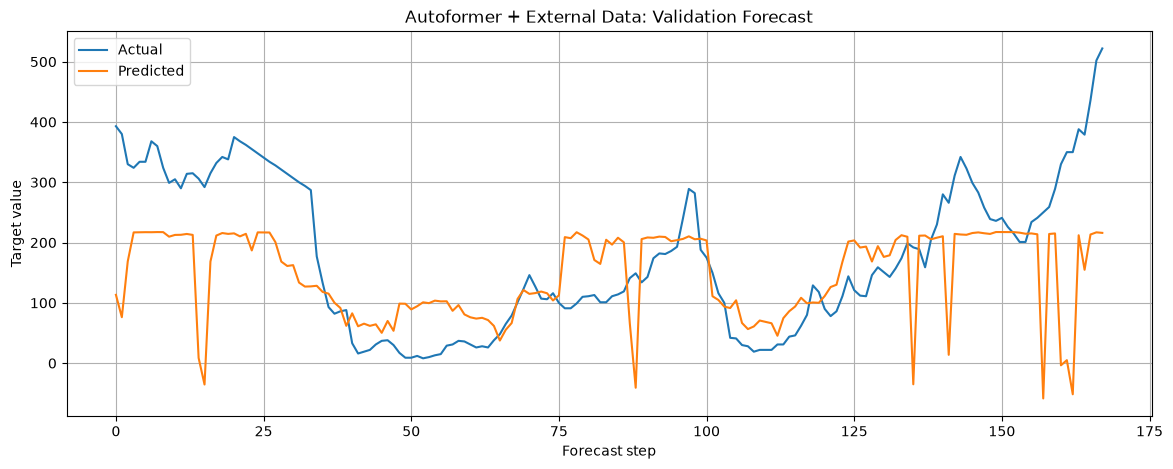

In [53]:
import matplotlib.pyplot as plt

prediction = validation_result_external["prediction"]
actual = validation_result_external["actual"]

plt.figure(figsize=(14, 5))

plt.plot(actual, label="Actual")
plt.plot(prediction, label="Predicted")

plt.xlabel("Forecast step")
plt.ylabel("Target value")
plt.title("Autoformer + External Data: Validation Forecast")
plt.legend()
plt.grid(True)
plt.show()

In [47]:
def create_dataloader_for_origin(
    y,
    external_features,
    origin,
    context_length=336,
    horizon=168,
    stride=8,
    batch_size=32
):
    X_y, X_ext, X_future_ext, targets = create_training_windows(
        y,
        external_features,
        origin,
        context_length,
        horizon,
        stride
    )

    dataset = ForecastDataset(
        X_y,
        X_ext,
        X_future_ext,
        targets
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    return loader

In [64]:
results_external = []

for i, origin in enumerate(origins):

    print("=" * 60)
    print(f"VALIDATION ORIGIN {i + 1}/5")
    print(f"Origin: {origin}")

    train_loader_origin = create_dataloader_for_origin(
        y=y,
        external_features=X_external,
        origin=origin,
        context_length=L,
        horizon=H,
        stride=8,
        batch_size=32
    )

    print(f"Training windows: {len(train_loader_origin.dataset)}")

    model = create_autoformer(
        use_external=True,
        seed=0
    )

    train_model(
        model=model,
        train_loader=train_loader_origin,
        device=device,
        epochs=10,
        learning_rate=1e-3,
        weight_decay=1e-4
    )

    result = evaluate_model_at_origin(
        model=model,
        y=y,
        external_features=X_external,
        origin=origin,
        context_length=L,
        horizon=H,
        device=device
    )

    results_external.append({
        "origin": origin,
        "MAE": result["MAE"],
        "RMSE": result["RMSE"],
        "sMAPE": result["sMAPE"]
    })

    print(
        f"MAE: {result['MAE']:.4f} | "
        f"RMSE: {result['RMSE']:.4f} | "
        f"sMAPE: {result['sMAPE']:.4f}"
    )

VALIDATION ORIGIN 1/5
Origin: 42816
Training windows: 5290
Epoch 1/10 - Loss: 15203.6521
Epoch 2/10 - Loss: 11065.2019
Epoch 3/10 - Loss: 9341.4283
Epoch 4/10 - Loss: 8330.8629
Epoch 5/10 - Loss: 7498.1768
Epoch 6/10 - Loss: 7038.5947
Epoch 7/10 - Loss: 6706.8613
Epoch 8/10 - Loss: 6522.7319
Epoch 9/10 - Loss: 6371.0550
Epoch 10/10 - Loss: 6175.3496
MAE: 83.6178 | RMSE: 115.0260 | sMAPE: 58.5191
VALIDATION ORIGIN 2/5
Origin: 42984
Training windows: 5311
Epoch 1/10 - Loss: 15289.2642
Epoch 2/10 - Loss: 11109.0786
Epoch 3/10 - Loss: 9939.8107
Epoch 4/10 - Loss: 9155.4877
Epoch 5/10 - Loss: 8286.6941
Epoch 6/10 - Loss: 7444.5825
Epoch 7/10 - Loss: 7037.7196
Epoch 8/10 - Loss: 6787.5066
Epoch 9/10 - Loss: 6552.7394
Epoch 10/10 - Loss: 6396.6786
MAE: 71.5540 | RMSE: 91.5439 | sMAPE: 92.4661
VALIDATION ORIGIN 3/5
Origin: 43152
Training windows: 5332
Epoch 1/10 - Loss: 15317.8315
Epoch 2/10 - Loss: 11220.1100
Epoch 3/10 - Loss: 9475.2939
Epoch 4/10 - Loss: 8548.7757
Epoch 5/10 - Loss: 7872.28

In [65]:
results_external_df = pd.DataFrame(results_external)

print(results_external_df)

print("\n=== AVERAGE ACROSS 5 VALIDATION ORIGINS ===")
print(f"MAE:   {results_external_df['MAE'].mean():.4f}")
print(f"RMSE:  {results_external_df['RMSE'].mean():.4f}")
print(f"sMAPE: {results_external_df['sMAPE'].mean():.4f}")

   origin        MAE        RMSE      sMAPE
0   42816  83.617805  115.025970  58.519066
1   42984  71.553955   91.543854  92.466148
2   43152  75.301170   96.988136  92.324463
3   43320  54.604389   66.269234  97.014359
4   43488  54.028408   62.872658  88.566986

=== AVERAGE ACROSS 5 VALIDATION ORIGINS ===
MAE:   67.8212
RMSE:  86.5400
sMAPE: 85.7782


In [66]:
results_no_external = []

for i, origin in enumerate(origins):

    print("=" * 60)
    print(f"NO-EXTERNAL VALIDATION ORIGIN {i + 1}/5")
    print(f"Origin: {origin}")

    train_loader_origin = create_dataloader_for_origin(
        y=y,
        external_features=X_external,
        origin=origin,
        context_length=L,
        horizon=H,
        stride=8,
        batch_size=32
    )

    print(f"Training windows: {len(train_loader_origin.dataset)}")

    model = create_autoformer(
        use_external=False,
        seed=0
    )

    train_model(
        model=model,
        train_loader=train_loader_origin,
        device=device,
        epochs=10,
        learning_rate=1e-3,
        weight_decay=1e-4
    )

    result = evaluate_model_at_origin(
        model=model,
        y=y,
        external_features=X_external,
        origin=origin,
        context_length=L,
        horizon=H,
        device=device
    )

    results_no_external.append({
        "origin": origin,
        "MAE": result["MAE"],
        "RMSE": result["RMSE"],
        "sMAPE": result["sMAPE"]
    })

    print(
        f"MAE: {result['MAE']:.4f} | "
        f"RMSE: {result['RMSE']:.4f} | "
        f"sMAPE: {result['sMAPE']:.4f}"
    )

NO-EXTERNAL VALIDATION ORIGIN 1/5
Origin: 42816
Training windows: 5290
Epoch 1/10 - Loss: 16152.0802
Epoch 2/10 - Loss: 13336.6120
Epoch 3/10 - Loss: 9417.3304
Epoch 4/10 - Loss: 9433.3304
Epoch 5/10 - Loss: 8874.3265
Epoch 6/10 - Loss: 8650.6952
Epoch 7/10 - Loss: 8527.1771
Epoch 8/10 - Loss: 8427.5482
Epoch 9/10 - Loss: 8309.1672
Epoch 10/10 - Loss: 8264.2601
MAE: 117.6533 | RMSE: 151.3844 | sMAPE: 80.4600
NO-EXTERNAL VALIDATION ORIGIN 2/5
Origin: 42984
Training windows: 5311
Epoch 1/10 - Loss: 16081.4998
Epoch 2/10 - Loss: 13092.7805
Epoch 3/10 - Loss: 11341.0068
Epoch 4/10 - Loss: 9618.5705
Epoch 5/10 - Loss: 8806.0072
Epoch 6/10 - Loss: 8465.5147
Epoch 7/10 - Loss: 8330.2922
Epoch 8/10 - Loss: 8270.0667
Epoch 9/10 - Loss: 8241.8088
Epoch 10/10 - Loss: 8232.1368
MAE: 94.0615 | RMSE: 114.1720 | sMAPE: 106.3309
NO-EXTERNAL VALIDATION ORIGIN 3/5
Origin: 43152
Training windows: 5332
Epoch 1/10 - Loss: 16216.4703
Epoch 2/10 - Loss: 13955.4226
Epoch 3/10 - Loss: 11196.6732
Epoch 4/10 - L

In [82]:
# External feature groups

continuous_features = [
    "feature_A",
    "feature_B",
    "feature_C",
    "feature_D",
    "feature_E",
    "feature_F"
]

binary_features = [
    "feature_G",
    "feature_H",
    "feature_I",
    "feature_J"
]

X_continuous = external[continuous_features].to_numpy(dtype=np.float32)
X_binary = external[binary_features].to_numpy(dtype=np.float32)

print("Continuous features:", continuous_features)
print("Continuous shape:", X_continuous.shape)

print("\nBinary features:", binary_features)
print("Binary shape:", X_binary.shape)

Continuous features: ['feature_A', 'feature_B', 'feature_C', 'feature_D', 'feature_E', 'feature_F']
Continuous shape: (43824, 6)

Binary features: ['feature_G', 'feature_H', 'feature_I', 'feature_J']
Binary shape: (43824, 4)


In [48]:
def create_autoformer(
    use_external=True,
    n_external_features=None,
    seed=0
):
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    if use_external:
        if n_external_features is None:
            n_external_features = 10
    else:
        n_external_features = 0

    model = SimpleAutoformer(
        context_length=336,
        horizon=168,
        n_external_features=n_external_features,
        d_model=128,
        n_heads=4,
        d_ff=256,
        n_layers=2,
        decomposition_kernel=25,
        top_k=5
    )

    return model

In [49]:
# Test Autoformer with 6 continuous external features

model_test_continuous = create_autoformer(
    use_external=True,
    n_external_features=6,
    seed=0
)

test_y = torch.randn(2, 336)

test_history_external = torch.randn(
    2, 336, 6
)

test_future_external = torch.randn(
    2, 168, 6
)

test_prediction = model_test_continuous(
    test_y,
    test_history_external,
    test_future_external
)

print("Target input shape:", test_y.shape)
print("Historical external shape:", test_history_external.shape)
print("Future external shape:", test_future_external.shape)
print("Prediction shape:", test_prediction.shape)

Target input shape: torch.Size([2, 336])
Historical external shape: torch.Size([2, 336, 6])
Future external shape: torch.Size([2, 168, 6])
Prediction shape: torch.Size([2, 168])


In [70]:
results_continuous = []

for i, origin in enumerate(origins):

    print("=" * 60)
    print(f"CONTINUOUS-ONLY VALIDATION ORIGIN {i + 1}/5")
    print(f"Origin: {origin}")

    train_loader_origin = create_dataloader_for_origin(
        y=y,
        external_features=X_continuous,
        origin=origin,
        context_length=L,
        horizon=H,
        stride=8,
        batch_size=32
    )

    print(f"Training windows: {len(train_loader_origin.dataset)}")

    model = create_autoformer(
        use_external=True,
        n_external_features=6,
        seed=0
    )

    train_model(
        model=model,
        train_loader=train_loader_origin,
        device=device,
        epochs=10,
        learning_rate=1e-3,
        weight_decay=1e-4
    )

    result = evaluate_model_at_origin(
        model=model,
        y=y,
        external_features=X_continuous,
        origin=origin,
        context_length=L,
        horizon=H,
        device=device
    )

    results_continuous.append({
        "origin": origin,
        "MAE": result["MAE"],
        "RMSE": result["RMSE"],
        "sMAPE": result["sMAPE"]
    })

    print(
        f"MAE: {result['MAE']:.4f} | "
        f"RMSE: {result['RMSE']:.4f} | "
        f"sMAPE: {result['sMAPE']:.4f}"
    )

CONTINUOUS-ONLY VALIDATION ORIGIN 1/5
Origin: 42816
Training windows: 5290
Epoch 1/10 - Loss: 15326.2044
Epoch 2/10 - Loss: 11324.1179
Epoch 3/10 - Loss: 9691.5546
Epoch 4/10 - Loss: 8995.7053
Epoch 5/10 - Loss: 8166.4403
Epoch 6/10 - Loss: 7501.7811
Epoch 7/10 - Loss: 7163.2405
Epoch 8/10 - Loss: 6934.3041
Epoch 9/10 - Loss: 6760.5760
Epoch 10/10 - Loss: 6563.5760
MAE: 85.4579 | RMSE: 112.2734 | sMAPE: 59.6377
CONTINUOUS-ONLY VALIDATION ORIGIN 2/5
Origin: 42984
Training windows: 5311
Epoch 1/10 - Loss: 15425.3622
Epoch 2/10 - Loss: 11049.9622
Epoch 3/10 - Loss: 9398.8602
Epoch 4/10 - Loss: 8327.1756
Epoch 5/10 - Loss: 7509.8062
Epoch 6/10 - Loss: 6904.6687
Epoch 7/10 - Loss: 6527.3919
Epoch 8/10 - Loss: 6226.5362
Epoch 9/10 - Loss: 6060.9975
Epoch 10/10 - Loss: 5794.3456
MAE: 71.0095 | RMSE: 93.2992 | sMAPE: 92.0318
CONTINUOUS-ONLY VALIDATION ORIGIN 3/5
Origin: 43152
Training windows: 5332
Epoch 1/10 - Loss: 15315.5744
Epoch 2/10 - Loss: 11109.0253
Epoch 3/10 - Loss: 9473.0190
Epoch 4

In [71]:
results_binary = []

for i, origin in enumerate(origins):

    print("=" * 60)
    print(f"BINARY-ONLY VALIDATION ORIGIN {i + 1}/5")
    print(f"Origin: {origin}")

    train_loader_origin = create_dataloader_for_origin(
        y=y,
        external_features=X_binary,
        origin=origin,
        context_length=L,
        horizon=H,
        stride=8,
        batch_size=32
    )

    print(f"Training windows: {len(train_loader_origin.dataset)}")

    model = create_autoformer(
        use_external=True,
        n_external_features=4,
        seed=0
    )

    train_model(
        model=model,
        train_loader=train_loader_origin,
        device=device,
        epochs=10,
        learning_rate=1e-3,
        weight_decay=1e-4
    )

    result = evaluate_model_at_origin(
        model=model,
        y=y,
        external_features=X_binary,
        origin=origin,
        context_length=L,
        horizon=H,
        device=device
    )

    results_binary.append({
        "origin": origin,
        "MAE": result["MAE"],
        "RMSE": result["RMSE"],
        "sMAPE": result["sMAPE"]
    })

    print(
        f"MAE: {result['MAE']:.4f} | "
        f"RMSE: {result['RMSE']:.4f} | "
        f"sMAPE: {result['sMAPE']:.4f}"
    )

BINARY-ONLY VALIDATION ORIGIN 1/5
Origin: 42816
Training windows: 5290
Epoch 1/10 - Loss: 16299.1403
Epoch 2/10 - Loss: 13955.0436
Epoch 3/10 - Loss: 9836.5067
Epoch 4/10 - Loss: 8785.7877
Epoch 5/10 - Loss: 8000.2760
Epoch 6/10 - Loss: 7640.1717
Epoch 7/10 - Loss: 7392.4209
Epoch 8/10 - Loss: 7219.1340
Epoch 9/10 - Loss: 7113.2240
Epoch 10/10 - Loss: 7027.3218
MAE: 109.5785 | RMSE: 144.6064 | sMAPE: 73.2345
BINARY-ONLY VALIDATION ORIGIN 2/5
Origin: 42984
Training windows: 5311
Epoch 1/10 - Loss: 16379.1404
Epoch 2/10 - Loss: 14345.1844
Epoch 3/10 - Loss: 11892.8095
Epoch 4/10 - Loss: 8575.1009
Epoch 5/10 - Loss: 7999.2732
Epoch 6/10 - Loss: 7690.0748
Epoch 7/10 - Loss: 7520.2648
Epoch 8/10 - Loss: 7404.2023
Epoch 9/10 - Loss: 7319.5787
Epoch 10/10 - Loss: 7290.5812
MAE: 69.8686 | RMSE: 104.0003 | sMAPE: 82.3832
BINARY-ONLY VALIDATION ORIGIN 3/5
Origin: 43152
Training windows: 5332
Epoch 1/10 - Loss: 15444.6716
Epoch 2/10 - Loss: 11877.0755
Epoch 3/10 - Loss: 10559.2394
Epoch 4/10 - Lo

In [72]:
results_binary_df = pd.DataFrame(results_binary)

print(results_binary_df)

print("\n=== BINARY-ONLY AVERAGE ACROSS 5 VALIDATION ORIGINS ===")
print(f"MAE:   {results_binary_df['MAE'].mean():.4f}")
print(f"RMSE:  {results_binary_df['RMSE'].mean():.4f}")
print(f"sMAPE: {results_binary_df['sMAPE'].mean():.4f}")

   origin         MAE        RMSE      sMAPE
0   42816  109.578529  144.606384  73.234451
1   42984   69.868553  104.000336  82.383240
2   43152   72.600121  102.054634  86.434517
3   43320   55.325371   67.722122  94.488731
4   43488   54.182072   70.979630  87.721107

=== BINARY-ONLY AVERAGE ACROSS 5 VALIDATION ORIGINS ===
MAE:   72.3109
RMSE:  97.8726
sMAPE: 84.8524


In [50]:
import random

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [51]:
def create_seeded_dataloader_for_origin(
    y,
    external_features,
    origin,
    context_length=336,
    horizon=168,
    stride=8,
    batch_size=32,
    seed=0
):
    set_seed(seed)

    X_y, X_ext, X_future_ext, targets = create_training_windows(
        y,
        external_features,
        origin,
        context_length,
        horizon,
        stride
    )

    dataset = ForecastDataset(
        X_y,
        X_ext,
        X_future_ext,
        targets
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    return loader

In [76]:
multi_seed_results = []

seeds = [0, 1, 2]

experiments = [
    {
        "name": "No external",
        "features": X_external,
        "n_features": 0,
        "use_external": False
    },
    {
        "name": "Continuous only",
        "features": X_continuous,
        "n_features": 6,
        "use_external": True
    },
    {
        "name": "All external",
        "features": X_external,
        "n_features": 10,
        "use_external": True
    }
]

for experiment in experiments:

    experiment_name = experiment["name"]
    external_features = experiment["features"]
    n_features = experiment["n_features"]
    use_external = experiment["use_external"]

    for seed in seeds:

        print("\n" + "#" * 70)
        print(f"EXPERIMENT: {experiment_name}")
        print(f"SEED: {seed}")
        print("#" * 70)

        for i, origin in enumerate(origins):

            print("\n" + "=" * 60)
            print(
                f"{experiment_name.upper()} | "
                f"SEED {seed} | "
                f"VALIDATION ORIGIN {i + 1}/5"
            )
            print(f"Origin: {origin}")

            set_seed(seed)

            train_loader_origin = create_seeded_dataloader_for_origin(
                y=y,
                external_features=external_features,
                origin=origin,
                context_length=L,
                horizon=H,
                stride=8,
                batch_size=32,
                seed=seed
            )

            print(
                f"Training windows: "
                f"{len(train_loader_origin.dataset)}"
            )

            model = create_autoformer(
                use_external=use_external,
                n_external_features=n_features,
                seed=seed
            )

            train_model(
                model=model,
                train_loader=train_loader_origin,
                device=device,
                epochs=10,
                learning_rate=1e-3,
                weight_decay=1e-4
            )

            result = evaluate_model_at_origin(
                model=model,
                y=y,
                external_features=external_features,
                origin=origin,
                context_length=L,
                horizon=H,
                device=device
            )

            multi_seed_results.append({
                "experiment": experiment_name,
                "seed": seed,
                "origin": origin,
                "MAE": result["MAE"],
                "RMSE": result["RMSE"],
                "sMAPE": result["sMAPE"]
            })

            print(
                f"MAE: {result['MAE']:.4f} | "
                f"RMSE: {result['RMSE']:.4f} | "
                f"sMAPE: {result['sMAPE']:.4f}"
            )


######################################################################
EXPERIMENT: No external
SEED: 0
######################################################################

NO EXTERNAL | SEED 0 | VALIDATION ORIGIN 1/5
Origin: 42816
Training windows: 5290
Epoch 1/10 - Loss: 16198.3087
Epoch 2/10 - Loss: 13963.0359
Epoch 3/10 - Loss: 10159.6633
Epoch 4/10 - Loss: 9667.7650
Epoch 5/10 - Loss: 8824.7738
Epoch 6/10 - Loss: 8532.4991
Epoch 7/10 - Loss: 8395.9993
Epoch 8/10 - Loss: 8279.8666
Epoch 9/10 - Loss: 8230.2898
Epoch 10/10 - Loss: 8198.5825
MAE: 115.2165 | RMSE: 148.5421 | sMAPE: 78.1890

NO EXTERNAL | SEED 0 | VALIDATION ORIGIN 2/5
Origin: 42984
Training windows: 5311
Epoch 1/10 - Loss: 16205.9800
Epoch 2/10 - Loss: 13708.5279
Epoch 3/10 - Loss: 10908.1745
Epoch 4/10 - Loss: 9410.3535
Epoch 5/10 - Loss: 8909.7680
Epoch 6/10 - Loss: 8547.6414
Epoch 7/10 - Loss: 8348.5876
Epoch 8/10 - Loss: 8263.1896
Epoch 9/10 - Loss: 8239.5153
Epoch 10/10 - Loss: 8231.3774
MAE: 93.0580 | RMSE: 11

In [77]:
multi_seed_df = pd.DataFrame(multi_seed_results)

print("\n=== ALL MULTI-SEED RESULTS ===")
print(multi_seed_df)


=== ALL MULTI-SEED RESULTS ===
         experiment  seed  origin         MAE        RMSE       sMAPE
0       No external     0   42816  115.216492  148.542053   78.189034
1       No external     0   42984   93.058022  113.838699  105.874840
2       No external     0   43152   92.745499  114.930199  103.317513
3       No external     0   43320   69.907639   79.187706  107.570778
4       No external     0   43488   67.432465   76.212524   98.659027
5       No external     1   42816  115.517242  148.511017   78.494484
6       No external     1   42984   93.926781  113.895187  106.334396
7       No external     1   43152   92.106079  115.007980  103.278175
8       No external     1   43320   70.045540   79.317810  107.634880
9       No external     1   43488   66.698593   75.523766   98.538902
10      No external     2   42816  114.205254  146.536880   77.307144
11      No external     2   42984   91.884361  113.482574  105.359398
12      No external     2   43152   91.126213  115.153625 

In [78]:
seed_summary = (
    multi_seed_df
    .groupby(["experiment", "seed"])[["MAE", "RMSE", "sMAPE"]]
    .mean()
    .reset_index()
)

print("\n=== AVERAGE ACROSS 5 VALIDATION ORIGINS ===")
print(seed_summary)


=== AVERAGE ACROSS 5 VALIDATION ORIGINS ===
        experiment  seed        MAE        RMSE      sMAPE
0     All external     0  68.631012   89.342506  85.647919
1     All external     1  74.610886   94.076859  90.163147
2     All external     2  75.723495   94.929855  92.091751
3  Continuous only     0  72.484215   91.651367  89.449059
4  Continuous only     1  67.634476   86.484818  85.916122
5  Continuous only     2  75.604599   96.686760  91.297630
6      No external     0  87.672020  106.542236  98.722244
7      No external     1  87.658852  106.451149  98.856163
8      No external     2  87.369583  106.576782  98.529419


In [79]:
final_multi_seed_summary = (
    multi_seed_df
    .groupby("experiment")[["MAE", "RMSE", "sMAPE"]]
    .agg(["mean", "std"])
)

print("\n=== FINAL MULTI-SEED SUMMARY ===")
print(final_multi_seed_summary)


=== FINAL MULTI-SEED SUMMARY ===
                       MAE                   RMSE                 sMAPE  \
                      mean        std        mean        std       mean   
experiment                                                                
All external     72.988472  16.735445   92.783073  25.095112  89.300934   
Continuous only  71.907761  12.647223   91.607651  21.449568  88.887604   
No external      87.566818  17.918886  106.523392  27.258986  98.702606   

                            
                       std  
experiment                  
All external     12.154703  
Continuous only  14.966865  
No external      11.151821  


In [52]:
import os
import torch

checkpoint_dir = "checkpoints_task2"
os.makedirs(checkpoint_dir, exist_ok=True)

print("Checkpoint directory:", checkpoint_dir)

Checkpoint directory: checkpoints_task2


In [53]:
def save_checkpoint(
    model,
    experiment_name,
    seed,
    origin,
    metrics,
    epochs=10
):
    filename = (
        f"{experiment_name}_"
        f"seed{seed}_"
        f"origin{origin}.pt"
    )

    path = os.path.join(checkpoint_dir, filename)

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "experiment": experiment_name,
            "seed": seed,
            "origin": origin,
            "epochs": epochs,
            "metrics": metrics,
        },
        path
    )

    print(f"Checkpoint saved: {path}")

In [54]:
class AutoformerDecomposition(nn.Module):

    def __init__(self, kernel_size):
        super().__init__()

        self.moving_average = nn.AvgPool1d(
            kernel_size=kernel_size,
            stride=1,
            padding=0
        )

        self.kernel_size = kernel_size

    def forward(self, x):
        # x: (B, L, D)

        x_t = x.transpose(1, 2)

        padding = (self.kernel_size - 1) // 2

        front = x_t[:, :, :1].repeat(
            1, 1, padding
        )

        end = x_t[:, :, -1:].repeat(
            1, 1, padding
        )

        x_padded = torch.cat(
            [front, x_t, end],
            dim=2
        )

        moving_mean = self.moving_average(
            x_padded
        )

        trend = moving_mean.transpose(1, 2)

        seasonal = x - trend

        return seasonal, trend

In [55]:
class AutoCorrelationLayer(nn.Module):

    def __init__(
        self,
        d_model,
        n_heads,
        top_k=6
    ):
        super().__init__()

        assert d_model % n_heads == 0

        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.top_k = top_k

        self.q_projection = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

        self.k_projection = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

        self.v_projection = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

        self.out_projection = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

    def forward(self, x):

        B, L, D = x.shape

        q = self.q_projection(x)
        k = self.k_projection(x)
        v = self.v_projection(x)

        q = q.view(
            B,
            L,
            self.n_heads,
            self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B,
            L,
            self.n_heads,
            self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B,
            L,
            self.n_heads,
            self.head_dim
        ).transpose(1, 2)

        # FFT-based correlation
        q_fft = torch.fft.rfft(q, dim=2)
        k_fft = torch.fft.rfft(k, dim=2)

        correlation_fft = (
            q_fft * torch.conj(k_fft)
        )

        correlation = torch.fft.irfft(
            correlation_fft,
            n=L,
            dim=2
        )

        # Aggregate correlation across
        # batch, heads and feature dimension
        delay_scores = correlation.mean(
            dim=(0, 1, 3)
        )

        k_top = min(
            self.top_k,
            L
        )

        top_values, top_delays = torch.topk(
            delay_scores,
            k=k_top
        )

        weights = torch.softmax(
            top_values,
            dim=0
        )

        output = torch.zeros_like(v)

        for weight, delay in zip(
            weights,
            top_delays
        ):

            delay = int(delay.item())

            shifted_v = torch.roll(
                v,
                shifts=-delay,
                dims=2
            )

            output = (
                output +
                weight * shifted_v
            )

        output = (
            output
            .transpose(1, 2)
            .contiguous()
            .view(B, L, D)
        )

        output = self.out_projection(output)

        return output

In [56]:
class AutoformerEncoderBlock(nn.Module):

    def __init__(
        self,
        d_model,
        n_heads,
        d_ff,
        decomposition_kernel=25,
        top_k=6
    ):
        super().__init__()

        self.auto_correlation = AutoCorrelationLayer(
            d_model=d_model,
            n_heads=n_heads,
            top_k=top_k
        )

        self.decomposition1 = AutoformerDecomposition(
            decomposition_kernel
        )

        self.decomposition2 = AutoformerDecomposition(
            decomposition_kernel
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )

    def forward(self, x):

        # --------------------------------
        # Auto-Correlation
        # --------------------------------

        seasonal = x + self.auto_correlation(
            x
        )

        seasonal, trend1 = self.decomposition1(
            seasonal
        )

        # --------------------------------
        # Feed-forward network
        # --------------------------------

        seasonal = seasonal + self.ffn(
            self.norm1(seasonal)
        )

        seasonal, trend2 = self.decomposition2(
            seasonal
        )

        # --------------------------------
        # Progressive trend accumulation
        # --------------------------------

        trend = trend1 + trend2

        seasonal = self.norm2(seasonal)

        return seasonal, trend

In [57]:
class ImprovedAutoformer(nn.Module):

    def __init__(
        self,
        context_length=336,
        horizon=168,
        n_external_features=6,
        d_model=128,
        n_heads=4,
        d_ff=256,
        n_layers=2,
        decomposition_kernel=25,
        top_k=6
    ):
        super().__init__()

        self.context_length = context_length
        self.horizon = horizon
        self.n_external_features = n_external_features
        self.d_model = d_model

        input_dim = 1 + n_external_features

        self.input_projection = nn.Linear(
            input_dim,
            d_model
        )

        self.future_projection = nn.Linear(
            n_external_features,
            d_model
        )

        self.encoder_position = nn.Parameter(
            torch.randn(
                1,
                context_length,
                d_model
            ) * 0.02
        )

        self.decoder_position = nn.Parameter(
            torch.randn(
                1,
                horizon,
                d_model
            ) * 0.02
        )

        self.encoder_layers = nn.ModuleList([
            AutoformerEncoderBlock(
                d_model=d_model,
                n_heads=n_heads,
                d_ff=d_ff,
                decomposition_kernel=decomposition_kernel,
                top_k=top_k
            )
            for _ in range(n_layers)
        ])

        self.trend_projection = nn.Linear(
            d_model,
            d_model
        )

        self.seasonal_projection = nn.Linear(
            d_model,
            d_model
        )

        self.output_projection = nn.Linear(
            d_model,
            1
        )

    def forward(
        self,
        history_y,
        history_external,
        future_external
    ):

        # --------------------------------
        # Encoder input
        # --------------------------------

        history_y = history_y.unsqueeze(-1)

        encoder_input = torch.cat(
            [
                history_y,
                history_external
            ],
            dim=-1
        )

        x = self.input_projection(
            encoder_input
        )

        x = (
            x +
            self.encoder_position
        )

        # --------------------------------
        # Progressive Autoformer encoder
        # --------------------------------

        accumulated_trend = torch.zeros_like(x)

        for layer in self.encoder_layers:

            x, trend = layer(x)

            accumulated_trend = (
                accumulated_trend +
                trend
            )

        # --------------------------------
        # Decoder seasonal component
        # --------------------------------

        future_x = self.future_projection(
            future_external
        )

        future_x = (
            future_x +
            self.decoder_position
        )

        # Use the latest encoder seasonal
        # representation as the starting point
        recent_seasonal = x[:, -1:, :]

        decoder_seasonal = (
            future_x +
            recent_seasonal
        )

        # --------------------------------
        # Forecast seasonal component
        # --------------------------------

        seasonal_context = (
            decoder_seasonal
        )

        seasonal_context = self.seasonal_projection(
            seasonal_context
        )

        # --------------------------------
        # Forecast trend component
        # --------------------------------

        recent_trend = (
            accumulated_trend[:, -1:, :]
        )

        trend_context = recent_trend.expand(
            -1,
            self.horizon,
            -1
        )

        trend_context = self.trend_projection(
            trend_context
        )

        # --------------------------------
        # Combine
        # --------------------------------

        combined = (
            seasonal_context +
            trend_context
        )

        output = self.output_projection(
            combined
        )

        return output.squeeze(-1)

In [58]:
def create_improved_autoformer(
    n_external_features=6,
    seed=0
):

    set_seed(seed)

    model = ImprovedAutoformer(
        context_length=336,
        horizon=168,
        n_external_features=n_external_features,
        d_model=128,
        n_heads=4,
        d_ff=256,
        n_layers=2,
        decomposition_kernel=25,
        top_k=6
    )

    return model

In [59]:
model_test = create_improved_autoformer(
    n_external_features=6,
    seed=0
)

test_y = torch.randn(
    2,
    336
)

test_history_external = torch.randn(
    2,
    336,
    6
)

test_future_external = torch.randn(
    2,
    168,
    6
)

with torch.no_grad():

    test_prediction = model_test(
        test_y,
        test_history_external,
        test_future_external
    )

print("Target input shape:", test_y.shape)
print(
    "Historical external shape:",
    test_history_external.shape
)
print(
    "Future external shape:",
    test_future_external.shape
)
print(
    "Prediction shape:",
    test_prediction.shape
)

Target input shape: torch.Size([2, 336])
Historical external shape: torch.Size([2, 336, 6])
Future external shape: torch.Size([2, 168, 6])
Prediction shape: torch.Size([2, 168])


In [83]:
sanity_loader = create_seeded_dataloader_for_origin(
    y,
    X_continuous,
    origin=origins[0],
    context_length=336,
    horizon=168,
    stride=8,
    batch_size=32,
    seed=0
)

sanity_model = create_improved_autoformer(
    n_external_features=6,
    seed=0
)

sanity_model = sanity_model.to(device)

sanity_losses = train_model(
    sanity_model,
    sanity_loader,
    device=device,
    epochs=3,
    learning_rate=0.001,
    weight_decay=0.0001
)

Epoch 1/3 - Loss: 9926.9518
Epoch 2/3 - Loss: 7168.0565
Epoch 3/3 - Loss: 6297.6282


In [100]:
sanity_metrics = evaluate_model_at_origin(
    sanity_model,
    y,
    X_continuous,
    origin=origins[0],
    context_length=336,
    horizon=168,
    device=device
)

print("Sanity validation results:")
print("MAE:", sanity_metrics["MAE"])
print("RMSE:", sanity_metrics["RMSE"])
print("sMAPE:", sanity_metrics["sMAPE"])

Sanity validation results:
MAE: 91.6818
RMSE: 110.03905
sMAPE: 62.266994


In [60]:
import os

checkpoint_dir = "checkpoints_task2"
os.makedirs(checkpoint_dir, exist_ok=True)

print("Checkpoint directory:", checkpoint_dir)

Checkpoint directory: checkpoints_task2


In [61]:
def save_model_checkpoint(
    model,
    experiment_name,
    seed,
    origin,
    epochs,
    metrics,
    loss_history
):
    filename = (
        f"{experiment_name}_"
        f"seed{seed}_"
        f"origin{origin}.pt"
    )

    path = os.path.join(
        checkpoint_dir,
        filename
    )

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "experiment_name": experiment_name,
            "seed": seed,
            "origin": origin,
            "epochs": epochs,
            "metrics": metrics,
            "loss_history": loss_history,
        },
        path
    )

    print(f"Saved checkpoint: {path}")

In [ ]:
save_model_checkpoint(
    model=sanity_model,
    experiment_name="improved_autoformer_sanity",
    seed=0,
    origin=origins[0],
    epochs=3,
    metrics=sanity_metrics,
    loss_history=sanity_losses
)

In [104]:
import os
import pandas as pd

# ---------------------------------------
# Experiment configuration
# ---------------------------------------

experiment_name = "improved_autoformer"

seeds = [0, 1, 2]

validation_origins = origins

EPOCHS = 10
BATCH_SIZE = 32
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
CONTEXT_LENGTH = 336
HORIZON = 168
STRIDE = 8

# ---------------------------------------
# Store all results here
# ---------------------------------------

experiment_results = []

# ---------------------------------------
# Run experiment
# ---------------------------------------

for seed in seeds:

    for origin in validation_origins:

        checkpoint_filename = (
            f"{experiment_name}_"
            f"seed{seed}_"
            f"origin{origin}.pt"
        )

        checkpoint_path = os.path.join(
            checkpoint_dir,
            checkpoint_filename
        )

        # ---------------------------------------
        # Check whether this run already exists
        # ---------------------------------------

        if os.path.exists(checkpoint_path):

            print("\n" + "=" * 70)
            print(
                f"Checkpoint already exists "
                f"→ skipping training"
            )
            print(
                f"Seed: {seed} | Origin: {origin}"
            )
            print("=" * 70)

            checkpoint = torch.load(
                checkpoint_path,
                map_location=device
            )

            metrics = checkpoint["metrics"]

            experiment_results.append({
                "experiment": experiment_name,
                "seed": seed,
                "origin": origin,
                "MAE": float(metrics["MAE"]),
                "RMSE": float(metrics["RMSE"]),
                "sMAPE": float(metrics["sMAPE"]),
                "epochs": checkpoint["epochs"]
            })

            continue

        # ---------------------------------------
        # Set random seeds
        # ---------------------------------------

        set_seed(seed)

        print("\n" + "=" * 70)
        print(
            f"Training Improved Autoformer"
        )
        print(
            f"Seed: {seed} | Origin: {origin}"
        )
        print("=" * 70)

        # ---------------------------------------
        # Create seeded DataLoader
        # ---------------------------------------

        train_loader = create_seeded_dataloader_for_origin(
            y,
            X_continuous,
            origin=origin,
            context_length=CONTEXT_LENGTH,
            horizon=HORIZON,
            stride=STRIDE,
            batch_size=BATCH_SIZE,
            seed=seed
        )

        print(
            f"Training windows: "
            f"{len(train_loader.dataset)}"
        )

        # ---------------------------------------
        # Create fresh model
        # ---------------------------------------

        model = create_improved_autoformer(
            n_external_features=6,
            seed=seed
        )

        model = model.to(device)

        # ---------------------------------------
        # Train
        # ---------------------------------------

        loss_history = train_model(
            model,
            train_loader,
            device=device,
            epochs=EPOCHS,
            learning_rate=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY
        )

        # ---------------------------------------
        # Evaluate
        # ---------------------------------------

        metrics = evaluate_model_at_origin(
            model,
            y,
            X_continuous,
            origin=origin,
            context_length=CONTEXT_LENGTH,
            horizon=HORIZON,
            device=device
        )

        print("\nValidation results:")
        print(f"MAE:   {metrics['MAE']:.4f}")
        print(f"RMSE:  {metrics['RMSE']:.4f}")
        print(f"sMAPE: {metrics['sMAPE']:.4f}")

        # ---------------------------------------
        # Save checkpoint
        # ---------------------------------------

        save_model_checkpoint(
            model=model,
            experiment_name=experiment_name,
            seed=seed,
            origin=origin,
            epochs=EPOCHS,
            metrics=metrics,
            loss_history=loss_history
        )

        # ---------------------------------------
        # Store result
        # ---------------------------------------

        experiment_results.append({
            "experiment": experiment_name,
            "seed": seed,
            "origin": origin,
            "MAE": float(metrics["MAE"]),
            "RMSE": float(metrics["RMSE"]),
            "sMAPE": float(metrics["sMAPE"]),
            "epochs": EPOCHS
        })

# ---------------------------------------
# Results DataFrame
# ---------------------------------------

experiment_results_df = pd.DataFrame(
    experiment_results
)

print("\n")
print("=" * 70)
print("EXPERIMENT COMPLETE")
print("=" * 70)

display(experiment_results_df)


Training Improved Autoformer
Seed: 0 | Origin: 42816
Training windows: 5290
Epoch 1/10 - Loss: 9926.9518
Epoch 2/10 - Loss: 7168.0565
Epoch 3/10 - Loss: 6297.6282
Epoch 4/10 - Loss: 5624.6034
Epoch 5/10 - Loss: 5381.1781
Epoch 6/10 - Loss: 5424.8265
Epoch 7/10 - Loss: 5393.1146
Epoch 8/10 - Loss: 5329.0364
Epoch 9/10 - Loss: 5288.0977
Epoch 10/10 - Loss: 5315.0312

Validation results:
MAE:   88.3733
RMSE:  99.0737
sMAPE: 60.7587
Saved checkpoint: checkpoints_task2\improved_autoformer_seed0_origin42816.pt

Training Improved Autoformer
Seed: 0 | Origin: 42984
Training windows: 5311
Epoch 1/10 - Loss: 10563.2256
Epoch 2/10 - Loss: 7159.0117
Epoch 3/10 - Loss: 6305.9553
Epoch 4/10 - Loss: 5721.8078
Epoch 5/10 - Loss: 5473.8267
Epoch 6/10 - Loss: 5461.2737
Epoch 7/10 - Loss: 5410.5381
Epoch 8/10 - Loss: 5386.0046
Epoch 9/10 - Loss: 5402.8876
Epoch 10/10 - Loss: 5293.6598

Validation results:
MAE:   51.4411
RMSE:  67.6175
sMAPE: 79.8975
Saved checkpoint: checkpoints_task2\improved_autoforme

,experiment,seed,origin,MAE,RMSE,sMAPE,epochs
0,improved_autoformer,0,42816,88.373314,99.073746,60.758663,10
1,improved_autoformer,0,42984,51.441071,67.617477,79.897461,10
2,improved_autoformer,0,43152,68.701973,84.651428,87.290886,10
3,improved_autoformer,0,43320,44.642448,56.000454,85.824966,10
4,improved_autoformer,0,43488,50.072475,58.664444,85.536865,10
5,improved_autoformer,1,42816,87.286636,98.654045,60.152107,10
6,improved_autoformer,1,42984,55.070301,70.977875,78.450859,10
7,improved_autoformer,1,43152,60.598724,84.921928,74.011452,10
8,improved_autoformer,1,43320,35.392555,51.309101,71.591957,10
9,improved_autoformer,1,43488,42.839386,51.419281,78.597969,10


In [105]:
seed_summary = (
    experiment_results_df
    .groupby("seed")[["MAE", "RMSE", "sMAPE"]]
    .mean()
    .reset_index()
)

print("Average across 5 validation origins:")
display(seed_summary)

Average across 5 validation origins:


,seed,MAE,RMSE,sMAPE
0,0,60.646256,73.201510,79.861768
1,1,56.237521,71.456446,72.560869
2,2,61.863425,73.596452,78.965879


In [106]:
overall_summary = (
    experiment_results_df[
        ["MAE", "RMSE", "sMAPE"]
    ]
    .mean()
)

print("Overall mean across")
print("3 seeds × 5 validation origins:")
print()
print(f"MAE:   {overall_summary['MAE']:.4f}")
print(f"RMSE:  {overall_summary['RMSE']:.4f}")
print(f"sMAPE: {overall_summary['sMAPE']:.4f}")

Overall mean across
3 seeds × 5 validation origins:

MAE:   59.5824
RMSE:  72.7515
sMAPE: 77.1295


In [85]:
def create_normalized_training_windows(
    y,
    external_features,
    end_index,
    context_length=336,
    horizon=168,
    stride=8
):
    X_y = []
    X_ext = []
    X_future_ext = []
    targets = []
    normalization_means = []
    normalization_stds = []

    start_positions = range(
        context_length,
        end_index - horizon + 1,
        stride
    )

    for end in start_positions:

        history_start = end - context_length
        future_end = end + horizon

        history_y = y[
            history_start:end
        ].copy()

        target_y = y[
            end:future_end
        ].copy()

        history_ext = external_features[
            history_start:end
        ].copy()

        future_ext = external_features[
            end:future_end
        ].copy()

        # --------------------------------
        # Calculate statistics ONLY from
        # the historical target
        # --------------------------------

        mean = history_y.mean()
        std = history_y.std()

        # Protect against zero variance
        if std < 1e-6:
            std = 1.0

        normalized_history = (
            history_y - mean
        ) / std

        normalized_target = (
            target_y - mean
        ) / std

        X_y.append(normalized_history)
        X_ext.append(history_ext)
        X_future_ext.append(future_ext)
        targets.append(normalized_target)

        normalization_means.append(mean)
        normalization_stds.append(std)

    return (
        np.array(X_y, dtype=np.float32),
        np.array(X_ext, dtype=np.float32),
        np.array(X_future_ext, dtype=np.float32),
        np.array(targets, dtype=np.float32),
        np.array(normalization_means, dtype=np.float32),
        np.array(normalization_stds, dtype=np.float32)
    )

In [86]:
class NormalizedForecastDataset(Dataset):

    def __init__(
        self,
        y_windows,
        external_windows,
        future_external_windows,
        targets,
        means,
        stds
    ):
        self.y_windows = torch.tensor(
            y_windows,
            dtype=torch.float32
        )

        self.external_windows = torch.tensor(
            external_windows,
            dtype=torch.float32
        )

        self.future_external_windows = torch.tensor(
            future_external_windows,
            dtype=torch.float32
        )

        self.targets = torch.tensor(
            targets,
            dtype=torch.float32
        )

        self.means = torch.tensor(
            means,
            dtype=torch.float32
        )

        self.stds = torch.tensor(
            stds,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.y_windows)

    def __getitem__(self, index):

        return (
            self.y_windows[index],
            self.external_windows[index],
            self.future_external_windows[index],
            self.targets[index],
            self.means[index],
            self.stds[index]
        )

In [87]:
def create_normalized_seeded_dataloader_for_origin(
    y,
    external_features,
    origin,
    context_length=336,
    horizon=168,
    stride=8,
    batch_size=32,
    seed=0
):
    set_seed(seed)

    (
        X_y,
        X_ext,
        X_future_ext,
        targets,
        means,
        stds
    ) = create_normalized_training_windows(
        y,
        external_features,
        origin,
        context_length,
        horizon,
        stride
    )

    dataset = NormalizedForecastDataset(
        X_y,
        X_ext,
        X_future_ext,
        targets,
        means,
        stds
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    return loader

In [88]:
def train_normalized_model(
    model,
    train_loader,
    device,
    epochs=10,
    learning_rate=0.001,
    weight_decay=0.0001
):

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    criterion = nn.MSELoss()

    model.train()

    loss_history = []

    for epoch in range(epochs):

        total_loss = 0.0

        for (
            history_y,
            history_external,
            future_external,
            targets,
            means,
            stds
        ) in train_loader:

            history_y = history_y.to(device)
            history_external = history_external.to(device)
            future_external = future_external.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            predictions = model(
                history_y,
                history_external,
                future_external
            )

            loss = criterion(
                predictions,
                targets
            )

            loss.backward()

            optimizer.step()

            total_loss += (
                loss.item() *
                history_y.size(0)
            )

        average_loss = (
            total_loss /
            len(train_loader.dataset)
        )

        loss_history.append(average_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"- Loss: {average_loss:.4f}"
        )

    return loss_history

In [89]:
def evaluate_normalized_model_at_origin(
    model,
    y,
    external_features,
    origin,
    context_length=336,
    horizon=168,
    device="cuda"
):

    model.eval()

    # --------------------------------
    # Historical target
    # --------------------------------

    history_y = y[
        origin - context_length:origin
    ].astype(np.float32)

    actual = y[
        origin:origin + horizon
    ].astype(np.float32)

    # --------------------------------
    # Normalize using history ONLY
    # --------------------------------

    mean = history_y.mean()
    std = history_y.std()

    if std < 1e-6:
        std = 1.0

    normalized_history = (
        history_y - mean
    ) / std

    # --------------------------------
    # External features
    # --------------------------------

    history_external = external_features[
        origin - context_length:origin
    ].astype(np.float32)

    future_external = external_features[
        origin:origin + horizon
    ].astype(np.float32)

    # --------------------------------
    # Convert to tensors
    # --------------------------------

    history_y_tensor = torch.tensor(
        normalized_history,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    history_external_tensor = torch.tensor(
        history_external,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    future_external_tensor = torch.tensor(
        future_external,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    # --------------------------------
    # Forecast
    # --------------------------------

    with torch.no_grad():

        normalized_prediction = model(
            history_y_tensor,
            history_external_tensor,
            future_external_tensor
        )

    normalized_prediction = (
        normalized_prediction
        .squeeze(0)
        .cpu()
        .numpy()
    )

    # --------------------------------
    # Convert back to original scale
    # --------------------------------

    prediction = (
        normalized_prediction * std
        + mean
    )

    # Target is nonnegative, so avoid
    # tiny negative numerical predictions.
    prediction = np.maximum(
        prediction,
        0
    )

    return {
        "MAE": mae(actual, prediction),
        "RMSE": rmse(actual, prediction),
        "sMAPE": smape(actual, prediction),
        "prediction": prediction,
        "actual": actual
    }

In [90]:
normalized_sanity_loader = (
    create_normalized_seeded_dataloader_for_origin(
        y,
        X_continuous,
        origin=origins[0],
        context_length=336,
        horizon=168,
        stride=8,
        batch_size=32,
        seed=0
    )
)

normalized_sanity_model = create_improved_autoformer(
    n_external_features=6,
    seed=0
)

normalized_sanity_model = (
    normalized_sanity_model.to(device)
)

In [113]:
normalized_sanity_losses = train_normalized_model(
    normalized_sanity_model,
    normalized_sanity_loader,
    device=device,
    epochs=3,
    learning_rate=0.001,
    weight_decay=0.0001
)

Epoch 1/3 - Loss: 2105.1831
Epoch 2/3 - Loss: 1.6330
Epoch 3/3 - Loss: 1.4806


In [114]:
normalized_sanity_metrics = (
    evaluate_normalized_model_at_origin(
        normalized_sanity_model,
        y,
        X_continuous,
        origin=origins[0],
        context_length=336,
        horizon=168,
        device=device
    )
)

print("Normalized sanity validation:")
print(
    "MAE:",
    normalized_sanity_metrics["MAE"]
)
print(
    "RMSE:",
    normalized_sanity_metrics["RMSE"]
)
print(
    "sMAPE:",
    normalized_sanity_metrics["sMAPE"]
)

Normalized sanity validation:
MAE: 101.35338
RMSE: 139.71542
sMAPE: 62.711926


In [115]:
normalized_10ep_loader = (
    create_normalized_seeded_dataloader_for_origin(
        y,
        X_continuous,
        origin=origins[0],
        context_length=336,
        horizon=168,
        stride=8,
        batch_size=32,
        seed=0
    )
)

normalized_10ep_model = create_improved_autoformer(
    n_external_features=6,
    seed=0
).to(device)

normalized_10ep_losses = train_normalized_model(
    normalized_10ep_model,
    normalized_10ep_loader,
    device=device,
    epochs=10,
    learning_rate=0.001,
    weight_decay=0.0001
)

Epoch 1/10 - Loss: 2105.1831
Epoch 2/10 - Loss: 1.6330
Epoch 3/10 - Loss: 1.4806
Epoch 4/10 - Loss: 1.4797
Epoch 5/10 - Loss: 1.3446
Epoch 6/10 - Loss: 1.3922
Epoch 7/10 - Loss: 1.3808
Epoch 8/10 - Loss: 1.3231
Epoch 9/10 - Loss: 1.4052
Epoch 10/10 - Loss: 1.3482


In [116]:
normalized_10ep_metrics = (
    evaluate_normalized_model_at_origin(
        normalized_10ep_model,
        y,
        X_continuous,
        origin=origins[0],
        context_length=336,
        horizon=168,
        device=device
    )
)

print("Normalized 10-epoch validation:")
print("MAE:", normalized_10ep_metrics["MAE"])
print("RMSE:", normalized_10ep_metrics["RMSE"])
print("sMAPE:", normalized_10ep_metrics["sMAPE"])

Normalized 10-epoch validation:
MAE: 72.14013
RMSE: 93.606094
sMAPE: 47.929676


In [117]:
normalized_results = []

normalization_checkpoint_dir = "checkpoints_task2_normalized"
os.makedirs(normalization_checkpoint_dir, exist_ok=True)

seeds = [0, 1, 2]

for seed in seeds:

    print("=" * 70)
    print(f"SEED {seed}")
    print("=" * 70)

    for origin in origins:

        print()
        print("-" * 70)
        print(f"Seed {seed} | Origin {origin}")
        print("-" * 70)

        # --------------------------------
        # Create normalized training data
        # --------------------------------

        train_loader = (
            create_normalized_seeded_dataloader_for_origin(
                y,
                X_continuous,
                origin=origin,
                context_length=336,
                horizon=168,
                stride=8,
                batch_size=32,
                seed=seed
            )
        )

        # --------------------------------
        # Create fresh model
        # --------------------------------

        model = create_improved_autoformer(
            n_external_features=6,
            seed=seed
        ).to(device)

        # --------------------------------
        # Train
        # --------------------------------

        loss_history = train_normalized_model(
            model,
            train_loader,
            device=device,
            epochs=10,
            learning_rate=0.001,
            weight_decay=0.0001
        )

        # --------------------------------
        # Evaluate
        # --------------------------------

        metrics = evaluate_normalized_model_at_origin(
            model,
            y,
            X_continuous,
            origin=origin,
            context_length=336,
            horizon=168,
            device=device
        )

        result = {
            "seed": seed,
            "origin": origin,
            "MAE": metrics["MAE"],
            "RMSE": metrics["RMSE"],
            "sMAPE": metrics["sMAPE"]
        }

        normalized_results.append(result)

        # --------------------------------
        # Save checkpoint
        # --------------------------------

        checkpoint_filename = (
            f"normalized_autoformer_"
            f"seed{seed}_"
            f"origin{origin}.pt"
        )

        checkpoint_path = os.path.join(
            normalization_checkpoint_dir,
            checkpoint_filename
        )

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "experiment_name": "normalized_autoformer",
                "seed": seed,
                "origin": origin,
                "epochs": 10,
                "context_length": 336,
                "horizon": 168,
                "stride": 8,
                "external_features": "A-F",
                "normalization": "window_relative_zscore",
                "metrics": result,
                "loss_history": loss_history
            },
            checkpoint_path
        )

        print(
            f"Validation: "
            f"MAE={metrics['MAE']:.4f}, "
            f"RMSE={metrics['RMSE']:.4f}, "
            f"sMAPE={metrics['sMAPE']:.4f}"
        )

        print(
            f"Saved: {checkpoint_path}"
        )

SEED 0

----------------------------------------------------------------------
Seed 0 | Origin 42816
----------------------------------------------------------------------
Epoch 1/10 - Loss: 2105.1831
Epoch 2/10 - Loss: 1.6330
Epoch 3/10 - Loss: 1.4806
Epoch 4/10 - Loss: 1.4797
Epoch 5/10 - Loss: 1.3446
Epoch 6/10 - Loss: 1.3922
Epoch 7/10 - Loss: 1.3808
Epoch 8/10 - Loss: 1.3231
Epoch 9/10 - Loss: 1.4052
Epoch 10/10 - Loss: 1.3482
Validation: MAE=72.1401, RMSE=93.6061, sMAPE=47.9297
Saved: checkpoints_task2_normalized\normalized_autoformer_seed0_origin42816.pt

----------------------------------------------------------------------
Seed 0 | Origin 42984
----------------------------------------------------------------------
Epoch 1/10 - Loss: 2071.4314
Epoch 2/10 - Loss: 1.7779
Epoch 3/10 - Loss: 1.5688
Epoch 4/10 - Loss: 1.4339
Epoch 5/10 - Loss: 1.3522
Epoch 6/10 - Loss: 1.3199
Epoch 7/10 - Loss: 1.2912
Epoch 8/10 - Loss: 1.3161
Epoch 9/10 - Loss: 1.3200
Epoch 10/10 - Loss: 1.3093
Val

In [118]:
normalized_results_df = pd.DataFrame(
    normalized_results
)

print(normalized_results_df)

print("\nOverall normalized results:")
print(
    normalized_results_df[
        ["MAE", "RMSE", "sMAPE"]
    ].mean()
)

    seed  origin         MAE        RMSE       sMAPE
0      0   42816   72.140129   93.606094   47.929676
1      0   42984   51.893402   73.876305   93.040604
2      0   43152  125.871025  139.230682  111.387291
3      0   43320   74.234009   81.541718  108.504593
4      0   43488   46.334682   55.209820   81.307060
5      1   42816   79.086800  102.269905   51.522064
6      1   42984   39.640781   55.388523  101.009773
7      1   43152   55.154167   80.779114   97.454414
8      1   43320   91.451111  100.114143  115.859116
9      1   43488   40.123547   55.489719  117.150726
10     2   42816   83.792328  100.431557   56.443375
11     2   42984   44.703411   66.526794  132.763672
12     2   43152  133.554672  148.907715  113.244591
13     2   43320   67.095375   76.020622  102.548393
14     2   43488   83.937767   93.482201  103.090523

Overall normalized results:
MAE      72.600876
RMSE     88.191658
sMAPE    95.550400
dtype: float32


In [119]:
print("\nResults by seed:")

print(
    normalized_results_df
    .groupby("seed")[["MAE", "RMSE", "sMAPE"]]
    .mean()
)


Results by seed:
            MAE       RMSE       sMAPE
seed                                  
0     74.094650  88.692917   88.433846
1     61.091278  78.808281   96.599220
2     82.616714  97.073776  101.618111


In [120]:
print("\nResults by origin:")

print(
    normalized_results_df
    .groupby("origin")[["MAE", "RMSE", "sMAPE"]]
    .mean()
)


Results by origin:
               MAE        RMSE       sMAPE
origin                                    
42816    78.339752   98.769188   51.965038
42984    45.412533   65.263878  108.938019
43152   104.859955  122.972504  107.362099
43320    77.593498   85.892159  108.970703
43488    56.798664   68.060577  100.516106


In [91]:
class ExternalTemporalEncoder(nn.Module):
    def __init__(
        self,
        n_features,
        d_model,
        kernel_size=7
    ):
        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels=n_features,
            out_channels=d_model,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )

        self.conv2 = nn.Conv1d(
            in_channels=d_model,
            out_channels=d_model,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )

        self.activation = nn.GELU()

    def forward(self, x):
        # x: (batch, sequence, features)

        x = x.transpose(1, 2)

        # (batch, features, sequence)
        x = self.conv1(x)
        x = self.activation(x)

        x = self.conv2(x)
        x = self.activation(x)

        # (batch, sequence, d_model)
        x = x.transpose(1, 2)

        return x

In [92]:
class TemporalExternalAutoformer(nn.Module):

    def __init__(
        self,
        context_length=336,
        horizon=168,
        n_external_features=6,
        d_model=128,
        n_heads=4,
        d_ff=256,
        n_layers=2,
        decomposition_kernel=25,
        top_k=6
    ):
        super().__init__()

        self.context_length = context_length
        self.horizon = horizon
        self.d_model = d_model
        self.n_external_features = n_external_features

        # --------------------------------
        # Target projection
        # --------------------------------

        self.target_projection = nn.Linear(
            1,
            d_model
        )

        # --------------------------------
        # Temporal external encoder
        # --------------------------------

        self.external_encoder = (
            ExternalTemporalEncoder(
                n_features=n_external_features,
                d_model=d_model,
                kernel_size=7
            )
        )

        # --------------------------------
        # Future external encoder
        # --------------------------------

        self.future_external_encoder = (
            ExternalTemporalEncoder(
                n_features=n_external_features,
                d_model=d_model,
                kernel_size=7
            )
        )

        # --------------------------------
        # Position information
        # --------------------------------

        self.encoder_position = nn.Parameter(
            torch.randn(
                1,
                context_length,
                d_model
            )
        )

        self.decoder_position = nn.Parameter(
            torch.randn(
                1,
                horizon,
                d_model
            )
        )

        # --------------------------------
        # Fusion
        # --------------------------------

        self.encoder_fusion = nn.Linear(
            2 * d_model,
            d_model
        )

        self.decoder_fusion = nn.Linear(
            2 * d_model,
            d_model
        )

        # --------------------------------
        # Decomposition
        # --------------------------------

        self.decomposition = (
            AutoformerDecomposition(
                decomposition_kernel
            )
        )

        # --------------------------------
        # Encoder
        # --------------------------------

        self.encoder_layers = nn.ModuleList([
            AutoformerEncoderBlock(
                d_model=d_model,
                n_heads=n_heads,
                d_ff=d_ff,
                decomposition_kernel=decomposition_kernel,
                top_k=top_k
            )
            for _ in range(n_layers)
        ])

        # --------------------------------
        # Forecast projections
        # --------------------------------

        self.seasonal_projection = nn.Linear(
            d_model,
            1
        )

        self.trend_projection = nn.Linear(
            d_model,
            1
        )

    def forward(
        self,
        history_y,
        history_external,
        future_external
    ):

        batch_size = history_y.size(0)

        # =================================
        # Encoder input
        # =================================

        target_input = history_y.unsqueeze(-1)

        target_encoded = self.target_projection(
            target_input
        )

        external_encoded = self.external_encoder(
            history_external
        )

        encoder_input = torch.cat(
            [
                target_encoded,
                external_encoded
            ],
            dim=-1
        )

        encoder_input = self.encoder_fusion(
            encoder_input
        )

        encoder_input = (
            encoder_input
            + self.encoder_position
        )

        # =================================
        # Initial decomposition
        # =================================

        seasonal, trend = self.decomposition(
            encoder_input
        )

        accumulated_trend = trend

        # =================================
        # Autoformer encoder
        # =================================

        for layer in self.encoder_layers:

            seasonal, layer_trend = layer(
                seasonal
            )

            accumulated_trend = (
                accumulated_trend
                + layer_trend
            )

        # =================================
        # Decoder external representation
        # =================================

        future_external_encoded = (
            self.future_external_encoder(
                future_external
            )
        )

        # =================================
        # Recent seasonal context
        # =================================

        latest_seasonal = seasonal[
            :, -1:, :
        ].repeat(
            1,
            self.horizon,
            1
        )

        decoder_input = torch.cat(
            [
                latest_seasonal,
                future_external_encoded
            ],
            dim=-1
        )

        decoder_input = self.decoder_fusion(
            decoder_input
        )

        decoder_input = (
            decoder_input
            + self.decoder_position
        )

        # =================================
        # Trend forecast
        # =================================

        latest_trend = accumulated_trend[
            :, -1:, :
        ].repeat(
            1,
            self.horizon,
            1
        )

        # =================================
        # Final forecast
        # =================================

        seasonal_forecast = (
            self.seasonal_projection(
                decoder_input
            ).squeeze(-1)
        )

        trend_forecast = (
            self.trend_projection(
                latest_trend
            ).squeeze(-1)
        )

        prediction = (
            seasonal_forecast
            + trend_forecast
        )

        return prediction

In [76]:
def create_temporal_external_autoformer(
    n_external_features=6,
    seed=0
):
    set_seed(seed)

    model = TemporalExternalAutoformer(
        context_length=336,
        horizon=168,
        n_external_features=n_external_features,
        d_model=128,
        n_heads=4,
        d_ff=256,
        n_layers=2,
        decomposition_kernel=25,
        top_k=6
    )

    return model

In [77]:
test_model = create_temporal_external_autoformer(
    n_external_features=6,
    seed=0
).to(device)

test_target = torch.randn(
    2, 336
).to(device)

test_history_external = torch.randn(
    2, 336, 6
).to(device)

test_future_external = torch.randn(
    2, 168, 6
).to(device)

with torch.no_grad():

    test_prediction = test_model(
        test_target,
        test_history_external,
        test_future_external
    )

print("Input target:", test_target.shape)
print(
    "History external:",
    test_history_external.shape
)
print(
    "Future external:",
    test_future_external.shape
)
print(
    "Prediction:",
    test_prediction.shape
)

Input target: torch.Size([2, 336])
History external: torch.Size([2, 336, 6])
Future external: torch.Size([2, 168, 6])
Prediction: torch.Size([2, 168])


In [93]:
total_parameters = sum(
    p.numel()
    for p in test_model.parameters()
    if p.requires_grad
)

print(
    f"Trainable parameters: "
    f"{total_parameters:,}"
)

Trainable parameters: 635,394


In [94]:
temporal_sanity_loader = (
    create_seeded_dataloader_for_origin(
        y,
        X_continuous,
        origin=origins[0],
        context_length=336,
        horizon=168,
        stride=8,
        batch_size=32,
        seed=0
    )
)

temporal_sanity_model = (
    create_temporal_external_autoformer(
        n_external_features=6,
        seed=0
    ).to(device)
)

In [133]:
temporal_sanity_losses = train_model(
    temporal_sanity_model,
    temporal_sanity_loader,
    device=device,
    epochs=3,
    learning_rate=0.001,
    weight_decay=0.0001
)

Epoch 1/3 - Loss: 7579.7862
Epoch 2/3 - Loss: 5588.9226
Epoch 3/3 - Loss: 4762.1385


In [134]:
temporal_sanity_metrics = (
    evaluate_model_at_origin(
        temporal_sanity_model,
        y,
        X_continuous,
        origins[0],
        context_length=336,
        horizon=168,
        device=device
    )
)

print("Temporal external sanity validation:")
print(
    "MAE:",
    temporal_sanity_metrics["MAE"]
)
print(
    "RMSE:",
    temporal_sanity_metrics["RMSE"]
)
print(
    "sMAPE:",
    temporal_sanity_metrics["sMAPE"]
)

Temporal external sanity validation:
MAE: 82.44735
RMSE: 93.309975
sMAPE: 57.804268


In [95]:
temporal_checkpoint_dir = "checkpoints_task2_temporal_external"
os.makedirs(
    temporal_checkpoint_dir,
    exist_ok=True
)

In [136]:
temporal_results = []

seeds = [0, 1, 2]

for seed in seeds:

    print("=" * 70)
    print(f"SEED {seed}")
    print("=" * 70)

    for origin in origins:

        print()
        print("-" * 70)
        print(f"Seed {seed} | Origin {origin}")
        print("-" * 70)

        # --------------------------------
        # Training data
        # --------------------------------

        train_loader = (
            create_seeded_dataloader_for_origin(
                y,
                X_continuous,
                origin=origin,
                context_length=336,
                horizon=168,
                stride=8,
                batch_size=32,
                seed=seed
            )
        )

        # --------------------------------
        # Fresh model
        # --------------------------------

        model = (
            create_temporal_external_autoformer(
                n_external_features=6,
                seed=seed
            ).to(device)
        )

        # --------------------------------
        # Train
        # --------------------------------

        loss_history = train_model(
            model,
            train_loader,
            device=device,
            epochs=10,
            learning_rate=0.001,
            weight_decay=0.0001
        )

        # --------------------------------
        # Evaluate
        # --------------------------------

        metrics = evaluate_model_at_origin(
            model,
            y,
            X_continuous,
            origin,
            context_length=336,
            horizon=168,
            device=device
        )

        result = {
            "seed": seed,
            "origin": origin,
            "MAE": metrics["MAE"],
            "RMSE": metrics["RMSE"],
            "sMAPE": metrics["sMAPE"]
        }

        temporal_results.append(result)

        # --------------------------------
        # Save checkpoint
        # --------------------------------

        checkpoint_filename = (
            f"temporal_external_autoformer_"
            f"seed{seed}_"
            f"origin{origin}.pt"
        )

        checkpoint_path = os.path.join(
            temporal_checkpoint_dir,
            checkpoint_filename
        )

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "experiment_name":
                    "temporal_external_autoformer",
                "seed": seed,
                "origin": origin,
                "epochs": 10,
                "context_length": 336,
                "horizon": 168,
                "stride": 8,
                "external_features": "A-F",
                "normalization": "none",
                "metrics": result,
                "loss_history": loss_history
            },
            checkpoint_path
        )

        print(
            f"Validation: "
            f"MAE={metrics['MAE']:.4f}, "
            f"RMSE={metrics['RMSE']:.4f}, "
            f"sMAPE={metrics['sMAPE']:.4f}"
        )

        print(
            f"Saved: {checkpoint_path}"
        )

SEED 0

----------------------------------------------------------------------
Seed 0 | Origin 42816
----------------------------------------------------------------------
Epoch 1/10 - Loss: 7579.7862
Epoch 2/10 - Loss: 5588.9226
Epoch 3/10 - Loss: 4762.1385
Epoch 4/10 - Loss: 4686.7057
Epoch 5/10 - Loss: 4563.5801
Epoch 6/10 - Loss: 4369.7491
Epoch 7/10 - Loss: 4438.0808
Epoch 8/10 - Loss: 4474.0915
Epoch 9/10 - Loss: 4352.7338
Epoch 10/10 - Loss: 4336.8416
Validation: MAE=71.1251, RMSE=85.8396, sMAPE=50.1635
Saved: checkpoints_task2_temporal_external\temporal_external_autoformer_seed0_origin42816.pt

----------------------------------------------------------------------
Seed 0 | Origin 42984
----------------------------------------------------------------------
Epoch 1/10 - Loss: 7655.4710
Epoch 2/10 - Loss: 5415.1797
Epoch 3/10 - Loss: 4621.0404
Epoch 4/10 - Loss: 4768.0137
Epoch 5/10 - Loss: 4412.0479
Epoch 6/10 - Loss: 4513.8628
Epoch 7/10 - Loss: 4345.9774
Epoch 8/10 - Loss: 4335

In [137]:
temporal_results_df = pd.DataFrame(
    temporal_results
)

print(temporal_results_df)

print("\nOverall temporal-external results:")
print(
    temporal_results_df[
        ["MAE", "RMSE", "sMAPE"]
    ].mean()
)

print("\nResults by seed:")
print(
    temporal_results_df
    .groupby("seed")[["MAE", "RMSE", "sMAPE"]]
    .mean()
)

print("\nResults by origin:")
print(
    temporal_results_df
    .groupby("origin")[["MAE", "RMSE", "sMAPE"]]
    .mean()
)

    seed  origin        MAE       RMSE       sMAPE
0      0   42816  71.125107  85.839638   50.163490
1      0   42984  37.431019  55.327938   60.752750
2      0   43152  38.365856  56.768623   52.853745
3      0   43320  59.084217  69.772720  160.596054
4      0   43488  27.193871  34.983482   63.633465
5      1   42816  81.844414  92.179230   57.713772
6      1   42984  38.524887  57.640984   61.502613
7      1   43152  37.632954  56.899513   49.832615
8      1   43320  36.584557  58.387047   93.434425
9      1   43488  35.846294  41.736168   77.322876
10     2   42816  86.985420  99.253159   59.886723
11     2   42984  36.510689  53.333946   64.133499
12     2   43152  41.698986  66.325500   65.780716
13     2   43320  42.150482  53.212418   85.514656
14     2   43488  52.574200  59.030914   89.098671

Overall temporal-external results:
MAE      48.236866
RMSE     62.712753
sMAPE    72.814667
dtype: float32

Results by seed:
            MAE       RMSE      sMAPE
seed                

In [96]:
# Final training configuration

FINAL_SEED = 0
FINAL_CONTEXT = 336
FINAL_HORIZON = 168
FINAL_STRIDE = 8
FINAL_EPOCHS = 10

print("Observed target length:", len(y))
print("Future horizon:", FINAL_HORIZON)
print("External data length:", len(X_continuous))

print(
    "Future external rows:",
    X_continuous[len(y):len(y) + FINAL_HORIZON].shape
)

Observed target length: 43656
Future horizon: 168
External data length: 43824
Future external rows: (168, 6)


In [97]:
final_train_loader = create_seeded_dataloader_for_origin(
    y,
    X_continuous,
    origin=len(y),
    context_length=FINAL_CONTEXT,
    horizon=FINAL_HORIZON,
    stride=FINAL_STRIDE,
    batch_size=32,
    seed=FINAL_SEED
)

print("Final training DataLoader created.")

Final training DataLoader created.


In [98]:
final_model = create_temporal_external_autoformer(
    n_external_features=6,
    seed=FINAL_SEED
).to(device)

print(
    "Final model parameters:",
    sum(p.numel() for p in final_model.parameters() if p.requires_grad)
)

Final model parameters: 635394


In [141]:
final_loss_history = train_model(
    final_model,
    final_train_loader,
    device=device,
    epochs=FINAL_EPOCHS,
    learning_rate=0.001,
    weight_decay=0.0001
)

Epoch 1/10 - Loss: 7838.5371
Epoch 2/10 - Loss: 5366.6737
Epoch 3/10 - Loss: 4749.3877
Epoch 4/10 - Loss: 4534.9989
Epoch 5/10 - Loss: 4446.2551
Epoch 6/10 - Loss: 4366.5172
Epoch 7/10 - Loss: 4382.8601
Epoch 8/10 - Loss: 4401.9159
Epoch 9/10 - Loss: 4298.3603
Epoch 10/10 - Loss: 4235.2704


In [ ]:
final_checkpoint_path = os.path.join(
    temporal_checkpoint_dir,
    "FINAL_temporal_external_autoformer_seed0.pt"
)

torch.save(
    {
        "model_state_dict": final_model.state_dict(),
        "experiment_name": "FINAL_temporal_external_autoformer",
        "seed": FINAL_SEED,
        "epochs": FINAL_EPOCHS,
        "context_length": FINAL_CONTEXT,
        "horizon": FINAL_HORIZON,
        "stride": FINAL_STRIDE,
        "external_features": "A-F",
        "normalization": "none",
        "n_parameters": sum(
            p.numel()
            for p in final_model.parameters()
            if p.requires_grad
        ),
        "loss_history": final_loss_history,
    },
    final_checkpoint_path
)

print("Saved final model:")
print(final_checkpoint_path)

In [143]:
history_y = y[-FINAL_CONTEXT:]

history_external = X_continuous[
    len(y) - FINAL_CONTEXT : len(y)
]

future_external = X_continuous[
    len(y) : len(y) + FINAL_HORIZON
]

print("history_y:", history_y.shape)
print("history_external:", history_external.shape)
print("future_external:", future_external.shape)

history_y: (336,)
history_external: (336, 6)
future_external: (168, 6)


In [144]:
final_model.eval()

history_y_tensor = torch.tensor(
    history_y,
    dtype=torch.float32
).unsqueeze(0).to(device)

history_external_tensor = torch.tensor(
    history_external,
    dtype=torch.float32
).unsqueeze(0).to(device)

future_external_tensor = torch.tensor(
    future_external,
    dtype=torch.float32
).unsqueeze(0).to(device)

with torch.no_grad():
    final_prediction = final_model(
        history_y_tensor,
        history_external_tensor,
        future_external_tensor
    )

final_prediction = (
    final_prediction
    .squeeze(0)
    .detach()
    .cpu()
    .numpy()
)

print("Prediction shape:", final_prediction.shape)
print("First 10 predictions:", final_prediction[:10])
print("Last 10 predictions:", final_prediction[-10:])
print("Min prediction:", final_prediction.min())
print("Max prediction:", final_prediction.max())

Prediction shape: (168,)
First 10 predictions: [15.154327   7.7322693  5.9811707 -2.4906921 -1.2040253 -1.1131439
  5.7118073  7.9728394  9.065353  11.191879 ]
Last 10 predictions: [-29.607452 -28.260834 -27.362    -25.733704 -21.826538 -26.683655
 -23.33548  -23.336304 -30.772766 -38.893066]
Min prediction: -38.893066
Max prediction: 158.32611


In [145]:
print("NaNs:", np.isnan(final_prediction).sum())
print("Infs:", np.isinf(final_prediction).sum())
print("Negative predictions:", (final_prediction < 0).sum())

print("\nPrediction statistics:")
print("Mean:", final_prediction.mean())
print("Median:", np.median(final_prediction))
print("Min:", final_prediction.min())
print("Max:", final_prediction.max())

NaNs: 0
Infs: 0
Negative predictions: 29

Prediction statistics:
Mean: 53.28591
Median: 38.532578
Min: -38.893066
Max: 158.32611


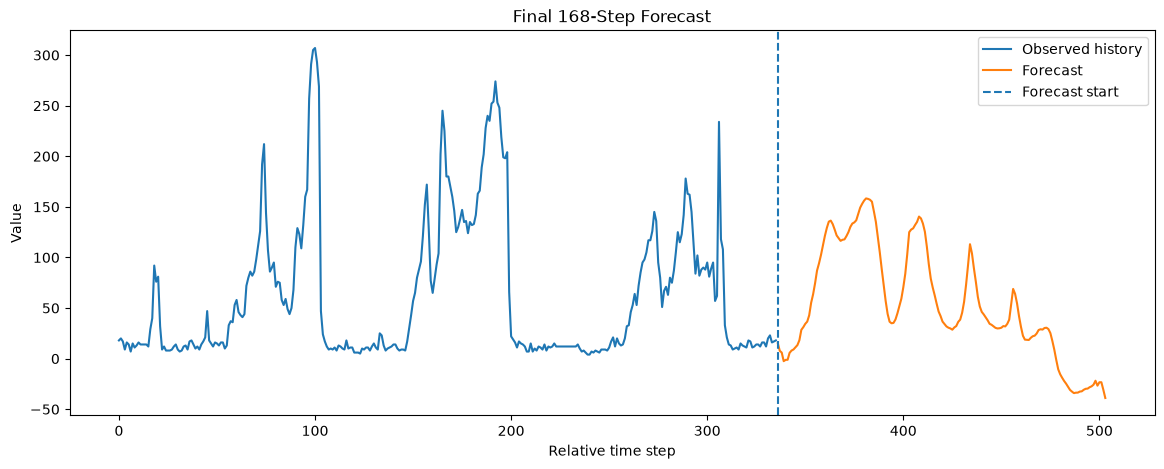

In [146]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    np.arange(FINAL_CONTEXT),
    history_y,
    label="Observed history"
)

plt.plot(
    np.arange(
        FINAL_CONTEXT,
        FINAL_CONTEXT + FINAL_HORIZON
    ),
    final_prediction,
    label="Forecast"
)

plt.axvline(
    FINAL_CONTEXT,
    linestyle="--",
    label="Forecast start"
)

plt.xlabel("Relative time step")
plt.ylabel("Value")
plt.title("Final 168-Step Forecast")
plt.legend()
plt.show()

In [147]:
final_prediction_clipped = np.maximum(
    final_prediction,
    0.0
)

print("Original negative predictions:",
      (final_prediction < 0).sum())

print("Negative predictions after clipping:",
      (final_prediction_clipped < 0).sum())

print("\nClipped prediction statistics:")
print("Mean:", final_prediction_clipped.mean())
print("Median:", np.median(final_prediction_clipped))
print("Min:", final_prediction_clipped.min())
print("Max:", final_prediction_clipped.max())

print("\nFirst 10:")
print(final_prediction_clipped[:10])

print("\nLast 10:")
print(final_prediction_clipped[-10:])

Original negative predictions: 29
Negative predictions after clipping: 0

Clipped prediction statistics:
Mean: 57.40293
Median: 38.532578
Min: 0.0
Max: 158.32611

First 10:
[15.154327   7.7322693  5.9811707  0.         0.         0.
  5.7118073  7.9728394  9.065353  11.191879 ]

Last 10:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [148]:
future_external_df = external[
    external["time_idx"].between(
        43657,
        43824
    )
].copy()

print("Future external shape:")
print(future_external_df.shape)

print("\nFuture external summary:")
print(
    future_external_df[
        continuous_features
    ].describe()
)

print("\nFirst 10 future external rows:")
print(
    future_external_df[
        ["time_idx"] + continuous_features
    ].head(10)
)

print("\nLast 10 future external rows:")
print(
    future_external_df[
        ["time_idx"] + continuous_features
    ].tail(10)
)

Future external shape:
(168, 11)

Future external summary:
        feature_A   feature_B    feature_C   feature_D  feature_E  feature_F
count  168.000000  168.000000   168.000000  168.000000      168.0      168.0
mean   -13.029762   -0.255952  1025.369048   33.163988        0.0        0.0
std      4.311835    4.684024     7.418668   62.030593        0.0        0.0
min    -27.000000   -8.000000  1011.000000    0.450000        0.0        0.0
25%    -14.000000   -4.000000  1018.000000    1.790000        0.0        0.0
50%    -12.000000   -2.000000  1027.500000    5.580000        0.0        0.0
75%    -10.000000    3.000000  1032.000000   22.802500        0.0        0.0
max     -7.000000   11.000000  1035.000000  249.850000        0.0        0.0

First 10 future external rows:
       time_idx  feature_A  feature_B  feature_C  feature_D  feature_E  \
43656     43657        -14        2.0     1033.0      75.55          0   
43657     43658        -14        1.0     1033.0      79.57         

In [149]:
recent_external_df = external[
    external["time_idx"].between(
        43321,
        43656
    )
].copy()

comparison = pd.DataFrame({
    "recent_mean": recent_external_df[
        continuous_features
    ].mean(),

    "future_mean": future_external_df[
        continuous_features
    ].mean(),

    "recent_std": recent_external_df[
        continuous_features
    ].std(),

    "future_std": future_external_df[
        continuous_features
    ].std()
})

print(comparison)

           recent_mean  future_mean  recent_std  future_std
feature_A   -15.782738   -13.029762    3.464593    4.311835
feature_B    -1.407738    -0.255952    4.188520    4.684024
feature_C  1027.732143  1025.369048    3.662595    7.418668
feature_D    81.802887    33.163988  116.394978   62.030593
feature_E     0.000000     0.000000    0.000000    0.000000
feature_F     0.000000     0.000000    0.000000    0.000000


In [150]:
# Final leaderboard forecast
leaderboard_forecast = np.maximum(
    final_prediction,
    0.0
)

# -----------------------------------------
# Verify length
# -----------------------------------------

assert len(leaderboard_forecast) == 168

# -----------------------------------------
# Verify test timestamps
# -----------------------------------------

expected_time_idx = np.arange(
    43657,
    43825
)

actual_time_idx = test["time_idx"].to_numpy()

assert np.array_equal(
    actual_time_idx,
    expected_time_idx
)

# -----------------------------------------
# Verify no invalid values
# -----------------------------------------

assert np.isfinite(
    leaderboard_forecast
).all()

assert (
    leaderboard_forecast >= 0
).all()

# -----------------------------------------
# Create comma-separated submission string
# -----------------------------------------

forecast_string = ",".join(
    f"{value:.6f}"
    for value in leaderboard_forecast
)

print("Number of forecast values:", len(leaderboard_forecast))
print("Number of characters:", len(forecast_string))

print("\nFIRST 300 CHARACTERS:")
print(forecast_string[:300])

print("\nLAST 300 CHARACTERS:")
print(forecast_string[-300:])

Number of forecast values: 168
Number of characters: 1688

FIRST 300 CHARACTERS:
15.154327,7.732269,5.981171,0.000000,0.000000,0.000000,5.711807,7.972839,9.065353,11.191879,13.379761,18.198090,28.483902,31.116211,34.401184,36.619247,42.813538,55.274628,63.638489,74.505203,87.046181,94.115471,102.331245,111.806190,121.280205,129.195129,135.394638,136.410675,132.940079,127.558952,

LAST 300 CHARACTERS:
.694016,30.273026,30.555588,29.196732,25.214600,17.482803,8.806091,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [151]:
submission_path = "task2_leaderboard_forecast.txt"

with open(
    submission_path,
    "w",
    encoding="utf-8"
) as f:
    f.write(forecast_string)

print("\nSaved submission file:")
print(submission_path)


Saved submission file:
task2_leaderboard_forecast.txt


In [152]:
forecast_check = pd.DataFrame({
    "time_idx": expected_time_idx,
    "forecast": leaderboard_forecast
})

print(forecast_check.head(10))
print()
print(forecast_check.tail(10))

print("\nForecast rows:", len(forecast_check))
print("Forecast sum:", leaderboard_forecast.sum())
print("Forecast mean:", leaderboard_forecast.mean())
print("Zeros:", (leaderboard_forecast == 0).sum())

   time_idx   forecast
0     43657  15.154327
1     43658   7.732269
2     43659   5.981171
3     43660   0.000000
4     43661   0.000000
5     43662   0.000000
6     43663   5.711807
7     43664   7.972839
8     43665   9.065353
9     43666  11.191879

     time_idx  forecast
158     43815       0.0
159     43816       0.0
160     43817       0.0
161     43818       0.0
162     43819       0.0
163     43820       0.0
164     43821       0.0
165     43822       0.0
166     43823       0.0
167     43824       0.0

Forecast rows: 168
Forecast sum: 9643.692
Forecast mean: 57.40293
Zeros: 29


In [100]:
# =========================================
# FINAL TRAINING — SEED 1
# =========================================

FINAL_SEED = 1
FINAL_CONTEXT = 336
FINAL_HORIZON = 168
FINAL_STRIDE = 8
FINAL_EPOCHS = 10

print("Observed target length:", len(y))
print("Future horizon:", FINAL_HORIZON)
print("External data length:", len(X_continuous))

# Create final training DataLoader
final_train_loader = create_seeded_dataloader_for_origin(
    y,
    X_continuous,
    origin=len(y),
    context_length=FINAL_CONTEXT,
    horizon=FINAL_HORIZON,
    stride=FINAL_STRIDE,
    batch_size=32,
    seed=FINAL_SEED
)

print("Final training DataLoader created.")

# Create SEED 1 model
final_model_seed1 = create_temporal_external_autoformer(
    n_external_features=6,
    seed=FINAL_SEED
).to(device)

print(
    "Final model parameters:",
    sum(
        p.numel()
        for p in final_model_seed1.parameters()
        if p.requires_grad
    )
)

# Train
final_loss_history_seed1 = train_model(
    final_model_seed1,
    final_train_loader,
    device=device,
    epochs=FINAL_EPOCHS,
    learning_rate=0.001,
    weight_decay=0.0001
)

Observed target length: 43656
Future horizon: 168
External data length: 43824
Final training DataLoader created.
Final model parameters: 635394
Epoch 1/10 - Loss: 7651.0670
Epoch 2/10 - Loss: 5801.4860
Epoch 3/10 - Loss: 4718.7086
Epoch 4/10 - Loss: 4673.3464
Epoch 5/10 - Loss: 4480.5967
Epoch 6/10 - Loss: 4636.4514
Epoch 7/10 - Loss: 4525.5515
Epoch 8/10 - Loss: 4335.2878
Epoch 9/10 - Loss: 4341.2786
Epoch 10/10 - Loss: 4263.9426


In [101]:
# =========================================
# FINAL FORECAST — SEED 1
# =========================================

history_y_seed1 = y[-FINAL_CONTEXT:]

history_external_seed1 = X_continuous[
    len(y) - FINAL_CONTEXT : len(y)
]

future_external_seed1 = X_continuous[
    len(y) : len(y) + FINAL_HORIZON
]

print("history_y:", history_y_seed1.shape)
print("history_external:", history_external_seed1.shape)
print("future_external:", future_external_seed1.shape)

final_model_seed1.eval()

history_y_tensor_seed1 = torch.tensor(
    history_y_seed1,
    dtype=torch.float32
).unsqueeze(0).to(device)

history_external_tensor_seed1 = torch.tensor(
    history_external_seed1,
    dtype=torch.float32
).unsqueeze(0).to(device)

future_external_tensor_seed1 = torch.tensor(
    future_external_seed1,
    dtype=torch.float32
).unsqueeze(0).to(device)

with torch.no_grad():
    final_prediction_seed1 = final_model_seed1(
        history_y_tensor_seed1,
        history_external_tensor_seed1,
        future_external_tensor_seed1
    )

final_prediction_seed1 = (
    final_prediction_seed1
    .squeeze(0)
    .detach()
    .cpu()
    .numpy()
)

print("Prediction shape:", final_prediction_seed1.shape)

print("\nFirst 10 predictions:")
print(final_prediction_seed1[:10])

print("\nLast 10 predictions:")
print(final_prediction_seed1[-10:])

print("\nPrediction statistics:")
print("Min:", final_prediction_seed1.min())
print("Max:", final_prediction_seed1.max())
print("Mean:", final_prediction_seed1.mean())
print("Median:", np.median(final_prediction_seed1))
print("NaNs:", np.isnan(final_prediction_seed1).sum())
print("Infs:", np.isinf(final_prediction_seed1).sum())
print("Negative predictions:", (final_prediction_seed1 < 0).sum())

history_y: (336,)
history_external: (336, 6)
future_external: (168, 6)
Prediction shape: (168,)

First 10 predictions:
[51.49672  51.60994  48.30905  45.181305 40.637802 36.49156  42.35875
 43.85942  44.231705 47.04146 ]

Last 10 predictions:
[ 8.499252  9.596664 10.734146 12.45932   4.042511  9.047592 11.507614
  9.580551 13.054672 10.663071]

Prediction statistics:
Min: 3.5544891
Max: 198.84863
Mean: 96.21402
Median: 84.00262
NaNs: 0
Infs: 0
Negative predictions: 0


In [102]:
# =========================================
# SEED 1 FORECAST — COMPARISON WITH RECENT DATA
# =========================================

recent_target = y[-168:]

print("Recent observed 168-step target:")
print("Mean:", recent_target.mean())
print("Median:", np.median(recent_target))
print("Min:", recent_target.min())
print("Max:", recent_target.max())

print("\nSeed 1 forecast:")
print("Mean:", final_prediction_seed1.mean())
print("Median:", np.median(final_prediction_seed1))
print("Min:", final_prediction_seed1.min())
print("Max:", final_prediction_seed1.max())

print("\nFirst 20 Seed 1 predictions:")
print(final_prediction_seed1[:20])

print("\nMiddle 20 Seed 1 predictions:")
print(final_prediction_seed1[74:94])

print("\nLast 20 Seed 1 predictions:")
print(final_prediction_seed1[-20:])

Recent observed 168-step target:
Mean: 69.65476
Median: 22.5
Min: 4.0
Max: 274.0

Seed 1 forecast:
Mean: 96.21402
Median: 84.00262
Min: 3.5544891
Max: 198.84863

First 20 Seed 1 predictions:
[ 51.49672   51.60994   48.30905   45.181305  40.637802  36.49156
  42.35875   43.85942   44.231705  47.04146   47.565613  51.416473
  69.462616  73.471436  78.889084  82.28166   90.20485  100.250496
 108.806015 119.29972 ]

Middle 20 Seed 1 predictions:
[178.1536   171.9345   159.18028  143.12262  126.33799  113.5594
 105.6151   101.00611   93.651955  87.16844   82.37958   79.156265
  75.70741   68.407196  64.17056   64.12723   63.529037  66.09096
  73.65297   81.30034 ]

Last 20 Seed 1 predictions:
[12.782608   9.61467    6.7863007  4.462143   3.5544891  4.226364
  5.1761475  7.3553925  6.937546   7.3810425  8.499252   9.596664
 10.734146  12.45932    4.042511   9.047592  11.507614   9.580551
 13.054672  10.663071 ]


In [103]:
# =========================================
# LEADERBOARD SUBMISSION — SEED 1
# =========================================

leaderboard_forecast_seed1 = final_prediction_seed1.copy()

# Verify exactly 168 predictions
assert len(leaderboard_forecast_seed1) == 168

# Verify timestamps
expected_time_idx = np.arange(43657, 43825)
actual_time_idx = test["time_idx"].to_numpy()

assert np.array_equal(
    actual_time_idx,
    expected_time_idx
)

# Verify valid numerical values
assert np.isfinite(
    leaderboard_forecast_seed1
).all()

# Target is nonnegative
assert (
    leaderboard_forecast_seed1 >= 0
).all()

# Create comma-separated submission string
forecast_string_seed1 = ",".join(
    f"{value:.6f}"
    for value in leaderboard_forecast_seed1
)

print("Number of forecast values:",
      len(leaderboard_forecast_seed1))

print("Number of characters:",
      len(forecast_string_seed1))

print("\nFIRST 300 CHARACTERS:")
print(forecast_string_seed1[:300])

print("\nLAST 300 CHARACTERS:")
print(forecast_string_seed1[-300:])

# Save separately so Seed 0 is not overwritten
submission_path_seed1 = "task2_leaderboard_forecast_seed1.txt"

with open(
    submission_path_seed1,
    "w",
    encoding="utf-8"
) as f:
    f.write(forecast_string_seed1)

print("\nSaved:")
print(submission_path_seed1)

Number of forecast values: 168
Number of characters: 1736

FIRST 300 CHARACTERS:
51.496719,51.609940,48.309052,45.181305,40.637802,36.491562,42.358749,43.859421,44.231705,47.041458,47.565613,51.416473,69.462616,73.471436,78.889084,82.281662,90.204849,100.250496,108.806015,119.299721,132.056763,139.409698,148.933929,156.580719,164.649063,172.037964,177.379883,178.555634,177.36415

LAST 300 CHARACTERS:
2532,77.034653,76.497635,73.071609,61.189713,48.179733,38.818649,31.113388,25.804306,22.966522,20.145599,16.479279,12.782608,9.614670,6.786301,4.462143,3.554489,4.226364,5.176147,7.355392,6.937546,7.381042,8.499252,9.596664,10.734146,12.459320,4.042511,9.047592,11.507614,9.580551,13.054672,10.663071

Saved:
task2_leaderboard_forecast_seed1.txt


In [104]:
# =========================================
# FINAL TRAINING — SEED 2
# =========================================

FINAL_SEED_2 = 2
FINAL_CONTEXT_2 = 336
FINAL_HORIZON_2 = 168
FINAL_STRIDE_2 = 8
FINAL_EPOCHS_2 = 10

print("Observed target length:", len(y))
print("Future horizon:", FINAL_HORIZON_2)
print("External data length:", len(X_continuous))

final_train_loader_seed2 = create_seeded_dataloader_for_origin(
    y,
    X_continuous,
    origin=len(y),
    context_length=FINAL_CONTEXT_2,
    horizon=FINAL_HORIZON_2,
    stride=FINAL_STRIDE_2,
    batch_size=32,
    seed=FINAL_SEED_2
)

print("Final training DataLoader created.")

final_model_seed2 = create_temporal_external_autoformer(
    n_external_features=6,
    seed=FINAL_SEED_2
).to(device)

print(
    "Final model parameters:",
    sum(
        p.numel()
        for p in final_model_seed2.parameters()
        if p.requires_grad
    )
)

final_loss_history_seed2 = train_model(
    final_model_seed2,
    final_train_loader_seed2,
    device=device,
    epochs=FINAL_EPOCHS_2,
    learning_rate=0.001,
    weight_decay=0.0001
)

Observed target length: 43656
Future horizon: 168
External data length: 43824
Final training DataLoader created.
Final model parameters: 635394
Epoch 1/10 - Loss: 8078.0435
Epoch 2/10 - Loss: 5735.7731
Epoch 3/10 - Loss: 5000.1728
Epoch 4/10 - Loss: 4670.7148
Epoch 5/10 - Loss: 4626.3356
Epoch 6/10 - Loss: 4413.2572
Epoch 7/10 - Loss: 4335.1690
Epoch 8/10 - Loss: 4378.3504
Epoch 9/10 - Loss: 4416.6607
Epoch 10/10 - Loss: 4352.4781


In [105]:
# =========================================
# FINAL FORECAST — SEED 2
# =========================================

history_y_seed2 = y[-FINAL_CONTEXT_2:]

history_external_seed2 = X_continuous[
    len(y) - FINAL_CONTEXT_2 : len(y)
]

future_external_seed2 = X_continuous[
    len(y) : len(y) + FINAL_HORIZON_2
]

final_model_seed2.eval()

history_y_tensor_seed2 = torch.tensor(
    history_y_seed2,
    dtype=torch.float32
).unsqueeze(0).to(device)

history_external_tensor_seed2 = torch.tensor(
    history_external_seed2,
    dtype=torch.float32
).unsqueeze(0).to(device)

future_external_tensor_seed2 = torch.tensor(
    future_external_seed2,
    dtype=torch.float32
).unsqueeze(0).to(device)

with torch.no_grad():
    final_prediction_seed2 = final_model_seed2(
        history_y_tensor_seed2,
        history_external_tensor_seed2,
        future_external_tensor_seed2
    )

final_prediction_seed2 = (
    final_prediction_seed2
    .squeeze(0)
    .detach()
    .cpu()
    .numpy()
)

print("Prediction shape:", final_prediction_seed2.shape)

print("\nFirst 10 predictions:")
print(final_prediction_seed2[:10])

print("\nLast 10 predictions:")
print(final_prediction_seed2[-10:])

print("\nPrediction statistics:")
print("Min:", final_prediction_seed2.min())
print("Max:", final_prediction_seed2.max())
print("Mean:", final_prediction_seed2.mean())
print("Median:", np.median(final_prediction_seed2))
print("NaNs:", np.isnan(final_prediction_seed2).sum())
print("Infs:", np.isinf(final_prediction_seed2).sum())
print("Negative predictions:", (final_prediction_seed2 < 0).sum())

Prediction shape: (168,)

First 10 predictions:
[45.44326  45.150894 43.27191  43.212105 38.308365 36.541656 40.642197
 42.832718 44.70855  46.01996 ]

Last 10 predictions:
[10.690262 12.132553 14.394394 17.114319 16.01419  16.036163 16.332153
 18.406677 19.371918 15.073105]

Prediction statistics:
Min: 8.737137
Max: 207.29982
Mean: 99.36742
Median: 83.75547
NaNs: 0
Infs: 0
Negative predictions: 0


In [106]:
# =========================================
# LEADERBOARD SUBMISSION — SEED 2
# =========================================

leaderboard_forecast_seed2 = final_prediction_seed2.copy()

# Verify exactly 168 predictions
assert len(leaderboard_forecast_seed2) == 168

# Verify timestamps
expected_time_idx = np.arange(43657, 43825)
actual_time_idx = test["time_idx"].to_numpy()

assert np.array_equal(
    actual_time_idx,
    expected_time_idx
)

# Verify valid numerical values
assert np.isfinite(
    leaderboard_forecast_seed2
).all()

# Target is nonnegative
assert (
    leaderboard_forecast_seed2 >= 0
).all()

# Create comma-separated submission string
forecast_string_seed2 = ",".join(
    f"{value:.6f}"
    for value in leaderboard_forecast_seed2
)

print("Number of forecast values:",
      len(leaderboard_forecast_seed2))

print("Number of characters:",
      len(forecast_string_seed2))

print("\nFIRST 300 CHARACTERS:")
print(forecast_string_seed2[:300])

print("\nLAST 300 CHARACTERS:")
print(forecast_string_seed2[-300:])

# Save separately
submission_path_seed2 = "task2_leaderboard_forecast_seed2.txt"

with open(
    submission_path_seed2,
    "w",
    encoding="utf-8"
) as f:
    f.write(forecast_string_seed2)

print("\nSaved:")
print(submission_path_seed2)

Number of forecast values: 168
Number of characters: 1745

FIRST 300 CHARACTERS:
45.443260,45.150894,43.271912,43.212105,38.308365,36.541656,40.642197,42.832718,44.708549,46.019958,49.335701,57.794510,71.060822,72.754036,76.345078,79.590866,83.746910,97.131805,107.327835,120.435669,133.425308,140.948975,151.323608,160.268295,167.884705,175.961838,182.721634,185.769592,185.479218

LAST 300 CHARACTERS:
5550,74.063217,68.369316,59.895126,50.796593,40.151855,33.747299,28.477142,24.061768,20.696274,17.342453,15.292480,13.732849,12.045380,10.159637,9.695770,8.737137,9.138641,9.770981,10.052826,10.163483,10.690262,12.132553,14.394394,17.114319,16.014191,16.036163,16.332153,18.406677,19.371918,15.073105

Saved:
task2_leaderboard_forecast_seed2.txt


In [107]:
class TrendDecomposedExternalAutoformer(nn.Module):
    def __init__(
        self,
        context_length=336,
        horizon=168,
        n_external_features=6,
        d_model=128,
        n_heads=4,
        d_ff=256,
        n_layers=2,
        decomposition_kernel=25,
        top_k=6
    ):
        super().__init__()

        self.context_length = context_length
        self.horizon = horizon
        self.n_external_features = n_external_features

        # ---------------------------------------------------------
        # 1. Explicit decomposition of external covariates
        # ---------------------------------------------------------
        self.external_decomposition = AutoformerDecomposition(
            kernel_size=decomposition_kernel
        )

        # Each external feature becomes:
        #   trend + seasonal
        # Therefore 6 -> 12 channels
        decomposed_features = n_external_features * 2

        # ---------------------------------------------------------
        # 2. Target and external encoders
        # ---------------------------------------------------------
        self.target_projection = nn.Linear(
            1, d_model
        )

        self.external_encoder = ExternalTemporalEncoder(
            n_features=decomposed_features,
            d_model=d_model,
            kernel_size=7
        )

        self.future_external_encoder = ExternalTemporalEncoder(
            n_features=decomposed_features,
            d_model=d_model,
            kernel_size=7
        )

        # ---------------------------------------------------------
        # 3. Fuse target + external representation
        # ---------------------------------------------------------
        self.encoder_fusion = nn.Linear(
            2 * d_model,
            d_model
        )

        self.decoder_fusion = nn.Linear(
            2 * d_model,
            d_model
        )

        # ---------------------------------------------------------
        # 4. Positional representations
        # ---------------------------------------------------------
        self.encoder_position = nn.Parameter(
            torch.zeros(1, context_length, d_model)
        )

        self.decoder_position = nn.Parameter(
            torch.zeros(1, horizon, d_model)
        )

        # ---------------------------------------------------------
        # 5. Initial target decomposition
        # ---------------------------------------------------------
        self.decomposition = AutoformerDecomposition(
            kernel_size=decomposition_kernel
        )

        # ---------------------------------------------------------
        # 6. Autoformer encoder blocks
        # ---------------------------------------------------------
        self.encoder_layers = nn.ModuleList([
            AutoformerEncoderBlock(
                d_model=d_model,
                n_heads=n_heads,
                d_ff=d_ff,
                top_k=top_k
            )
            for _ in range(n_layers)
        ])

        # ---------------------------------------------------------
        # 7. Output projections
        # ---------------------------------------------------------
        self.seasonal_projection = nn.Linear(
            d_model, 1
        )

        self.trend_projection = nn.Linear(
            d_model, 1
        )

        # ---------------------------------------------------------
        # 8. Initialize parameters
        # ---------------------------------------------------------
        nn.init.normal_(self.encoder_position, mean=0.0, std=0.02)
        nn.init.normal_(self.decoder_position, mean=0.0, std=0.02)

    def forward(self, target, external_history, external_future):

        # =========================================================
        # A. Explicitly decompose historical external covariates
        # =========================================================

        ext_hist_seasonal, ext_hist_trend = self.external_decomposition(
            external_history
        )

        # Shape:
        # ext_hist_seasonal = (B, 336, 6)
        # ext_hist_trend    = (B, 336, 6)

        ext_hist = torch.cat(
            [ext_hist_trend, ext_hist_seasonal],
            dim=-1
        )

        # Shape:
        # (B, 336, 12)

        # =========================================================
        # B. Encode target
        # =========================================================

        target_encoded = self.target_projection(
            target.unsqueeze(-1)
        )

        # Shape:
        # (B, 336, 128)

        # =========================================================
        # C. Encode decomposed historical external variables
        # =========================================================

        external_encoded = self.external_encoder(
            ext_hist
        )

        # Shape:
        # (B, 336, 128)

        # =========================================================
        # D. Fuse target + external information
        # =========================================================

        encoder_input = torch.cat(
            [target_encoded, external_encoded],
            dim=-1
        )

        encoder_input = self.encoder_fusion(
            encoder_input
        )

        encoder_input = (
            encoder_input
            + self.encoder_position
        )

        # =========================================================
        # E. Initial series decomposition
        # =========================================================

        seasonal, trend = self.decomposition(
            encoder_input
        )

        accumulated_trend = trend

        # =========================================================
        # F. Autoformer encoder
        # =========================================================

        for layer in self.encoder_layers:

            seasonal, layer_trend = layer(
                seasonal
            )

            accumulated_trend = (
                accumulated_trend
                + layer_trend
            )

        # =========================================================
        # G. Decompose future external covariates
        # =========================================================

        ext_future_seasonal, ext_future_trend = (
            self.external_decomposition(
                external_future
            )
        )

        ext_future = torch.cat(
            [ext_future_trend, ext_future_seasonal],
            dim=-1
        )

        # =========================================================
        # H. Encode future external variables
        # =========================================================

        future_external_encoded = (
            self.future_external_encoder(
                ext_future
            )
        )

        # =========================================================
        # I. Build decoder representation
        # =========================================================

        latest_seasonal = seasonal[:, -1:, :]

        decoder_seasonal = latest_seasonal.repeat(
            1, self.horizon, 1
        )

        decoder_input = torch.cat(
            [
                decoder_seasonal,
                future_external_encoded
            ],
            dim=-1
        )

        decoder_input = self.decoder_fusion(
            decoder_input
        )

        decoder_input = (
            decoder_input
            + self.decoder_position
        )

        # =========================================================
        # J. Forecast trend
        # =========================================================

        latest_trend = accumulated_trend[:, -1:, :]

        decoder_trend = latest_trend.repeat(
            1, self.horizon, 1
        )

        # =========================================================
        # K. Project seasonal + trend back to target
        # =========================================================

        seasonal_output = self.seasonal_projection(
            decoder_input
        )

        trend_output = self.trend_projection(
            decoder_trend
        )

        forecast = (
            seasonal_output
            + trend_output
        )

        return forecast.squeeze(-1)

In [108]:
ATTEMPT_4_SEED = 2

set_seed(ATTEMPT_4_SEED)

attempt4_model = TrendDecomposedExternalAutoformer(
    context_length=336,
    horizon=168,
    n_external_features=6,
    d_model=128,
    n_heads=4,
    d_ff=256,
    n_layers=2,
    decomposition_kernel=25,
    top_k=6
).to(device)

print(
    "Trainable parameters:",
    sum(p.numel() for p in attempt4_model.parameters()
        if p.requires_grad)
)

Trainable parameters: 646146


In [109]:
test_target = torch.randn(2, 336, device=device)
test_history_external = torch.randn(2, 336, 6, device=device)
test_future_external = torch.randn(2, 168, 6, device=device)

with torch.no_grad():
    test_output = attempt4_model(
        test_target,
        test_history_external,
        test_future_external
    )

print("Output shape:", test_output.shape)

Output shape: torch.Size([2, 168])


In [110]:
ATTEMPT_4_EPOCHS = 10

final_train_loader_attempt4 = create_seeded_dataloader_for_origin(
    y,
    X_continuous,
    origin=len(y),
    context_length=336,
    horizon=168,
    stride=8,
    batch_size=32,
    seed=ATTEMPT_4_SEED
)

attempt4_loss_history = train_model(
    attempt4_model,
    final_train_loader_attempt4,
    device=device,
    epochs=ATTEMPT_4_EPOCHS,
    learning_rate=0.001,
    weight_decay=0.0001
)

Epoch 1/10 - Loss: 6860.1155
Epoch 2/10 - Loss: 4853.8255
Epoch 3/10 - Loss: 4333.4814
Epoch 4/10 - Loss: 4210.7663
Epoch 5/10 - Loss: 4194.4145
Epoch 6/10 - Loss: 3984.9822
Epoch 7/10 - Loss: 3909.9469
Epoch 8/10 - Loss: 3905.4796
Epoch 9/10 - Loss: 3886.1498
Epoch 10/10 - Loss: 3853.8555


In [111]:
attempt4_model.eval()

with torch.no_grad():
    context_y = torch.tensor(
        y[-336:],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    history_external = torch.tensor(
        X_continuous[-336:],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    future_external = torch.tensor(
        X_continuous[len(y):len(y) + 168],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    attempt4_forecast = attempt4_model(
        context_y,
        history_external,
        future_external
    ).squeeze(0).cpu().numpy()

print("Shape:", attempt4_forecast.shape)

print("\nFirst 10:")
print(attempt4_forecast[:10])

print("\nLast 10:")
print(attempt4_forecast[-10:])

print("\nStatistics:")
print("Min:", attempt4_forecast.min())
print("Max:", attempt4_forecast.max())
print("Mean:", attempt4_forecast.mean())
print("Median:", np.median(attempt4_forecast))
print("Negative values:", (attempt4_forecast < 0).sum())

Shape: (168,)

First 10:
[56.697258 49.718674 51.542397 53.30571  60.265472 57.898117 54.513878
 54.926407 56.84562  58.506912]

Last 10:
[21.724228 23.060562 25.360352 27.46312  35.05136  39.430107 38.248466
 44.517586 46.83721  48.478325]

Statistics:
Min: 20.03392
Max: 255.64478
Mean: 113.57113
Median: 99.88913
Negative values: 0


In [112]:
attempt4_forecast_clipped = np.maximum(attempt4_forecast, 0)

attempt4_submission = ",".join(
    f"{float(v):.6f}"
    for v in attempt4_forecast_clipped
)

print("Number of forecast values:", len(attempt4_forecast_clipped))
print("String length:", len(attempt4_submission))

with open("task2_leaderboard_forecast_attempt4.txt", "w") as f:
    f.write(attempt4_submission)

print("\nFirst 5 values:")
print(attempt4_forecast_clipped[:5])

print("\nLast 5 values:")
print(attempt4_forecast_clipped[-5:])

Number of forecast values: 168
String length: 1763

First 5 values:
[56.697258 49.718674 51.542397 53.30571  60.265472]

Last 5 values:
[39.430107 38.248466 44.517586 46.83721  48.478325]


In [115]:
def evaluate_checkpoint_at_origin(
    model,
    y,
    X_external,
    origin,
    context_length,
    horizon,
    device
):
    model.eval()

    # Historical target context
    context_y = torch.tensor(
        y[origin - context_length:origin],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    # Historical external features
    history_external = torch.tensor(
        X_external[origin - context_length:origin],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    # Future external features
    future_external = torch.tensor(
        X_external[origin:origin + horizon],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    # Actual future target
    actual = y[origin:origin + horizon]

    with torch.no_grad():
        prediction = model(
            context_y,
            history_external,
            future_external
        )

    prediction = prediction.squeeze(0).cpu().numpy()

    return {
        "prediction": prediction,
        "actual": actual
    }

In [116]:
model_errors = []
persistence_errors = []

for seed in [0, 1, 2]:
    for origin in origins:

        model = create_temporal_external_autoformer(
            n_external_features=6,
            seed=seed
        ).to(device)

        checkpoint_path = (
            f"checkpoints_task2_temporal_external/"
            f"temporal_external_autoformer_seed{seed}_origin{origin}.pt"
        )

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        result = evaluate_checkpoint_at_origin(
            model=model,
            y=y,
            X_external=X_continuous,
            origin=origin,
            context_length=336,
            horizon=168,
            device=device
        )

        actual = result["actual"]
        prediction = result["prediction"]

        # Model error at every horizon step
        model_errors.append(
            (prediction - actual) ** 2
        )

        # Persistence prediction
        persistence_prediction = y[origin - 1]

        persistence_errors.append(
            (persistence_prediction - actual) ** 2
        )


# Convert to arrays
model_errors = np.asarray(model_errors)
persistence_errors = np.asarray(persistence_errors)

# RMSE at each forecast horizon
model_rmse_by_horizon = np.sqrt(
    np.mean(model_errors, axis=0)
)

persistence_rmse_by_horizon = np.sqrt(
    np.mean(persistence_errors, axis=0)
)

print("Horizon | Model RMSE | Persistence RMSE | Winner")
print("-" * 55)

for h in [1, 2, 3, 6, 12, 24, 48, 96, 168]:

    model_rmse = model_rmse_by_horizon[h - 1]
    persistence_rmse = persistence_rmse_by_horizon[h - 1]

    winner = (
        "Model"
        if model_rmse < persistence_rmse
        else "Persistence"
    )

    print(
        f"{h:7d} | "
        f"{model_rmse:10.2f} | "
        f"{persistence_rmse:17.2f} | "
        f"{winner}"
    )

Horizon | Model RMSE | Persistence RMSE | Winner
-------------------------------------------------------
      1 |     143.46 |             23.64 | Persistence
      2 |     133.68 |             37.44 | Persistence
      3 |     100.92 |             76.06 | Persistence
      6 |      51.19 |            224.96 | Model
     12 |      35.19 |            231.05 | Model
     24 |      54.21 |            218.93 | Model
     48 |      48.35 |            233.71 | Model
     96 |      54.10 |            248.72 | Model
    168 |     135.07 |            259.16 | Model


In [117]:
import numpy as np

seed1 = np.loadtxt(
    "task2_leaderboard_forecast_seed1.txt",
    delimiter=","
)

seed2 = np.loadtxt(
    "task2_leaderboard_forecast_seed2.txt",
    delimiter=","
)

assert len(seed1) == 168
assert len(seed2) == 168

ensemble_12 = (seed1 + seed2) / 2

print("Shape:", ensemble_12.shape)
print("Mean:", ensemble_12.mean())
print("Median:", np.median(ensemble_12))
print("Min:", ensemble_12.min())
print("Max:", ensemble_12.max())

Shape: (168,)
Mean: 97.7907141220238
Median: 83.4343685
Min: 6.4817505
Max: 203.0742265


In [118]:
last_observed = y[-1]

persistence_forecast = np.full(
    168,
    last_observed,
    dtype=np.float32
)

blended_forecast = ensemble_12.copy()

# Gradual transition from persistence to model
weights_model = np.ones(168)

weights_model[0] = 0.00   # horizon 1
weights_model[1] = 0.00   # horizon 2
weights_model[2] = 0.25   # horizon 3
weights_model[3] = 0.50   # horizon 4
weights_model[4] = 0.75   # horizon 5
weights_model[5:] = 1.00  # horizon 6 onward

blended_forecast = (
    weights_model * ensemble_12
    + (1 - weights_model) * persistence_forecast
)

blended_forecast = np.maximum(
    blended_forecast,
    0
)

print("Last observed value:", last_observed)

print("\nFirst 10 blended values:")
print(blended_forecast[:10])

print("\nLast 10 blended values:")
print(blended_forecast[-10:])

print("\nStatistics:")
print("Mean:", blended_forecast.mean())
print("Median:", np.median(blended_forecast))
print("Min:", blended_forecast.min())
print("Max:", blended_forecast.max())

Last observed value: 18.0

First 10 blended values:
[18.         18.         24.9476205  31.0983525  34.10481263 36.516609
 41.500473   43.3460695  44.470127   46.530708  ]

Last 10 blended values:
[ 9.594757  10.8646085 12.56427   14.7868195 10.028351  12.5418775
 13.9198835 13.993614  16.213295  12.868088 ]

Statistics:
Mean: 97.1945242924107
Median: 83.4343685
Min: 6.4817505
Max: 203.0742265


In [119]:
attempt4_final = np.maximum(
    blended_forecast,
    0
)

assert len(attempt4_final) == 168
assert np.isfinite(attempt4_final).all()
assert (attempt4_final >= 0).all()

attempt4_submission = ",".join(
    f"{float(v):.6f}"
    for v in attempt4_final
)

with open(
    "task2_leaderboard_forecast_attempt4_ensemble_blended.txt",
    "w"
) as f:
    f.write(attempt4_submission)

print("Number of values:", len(attempt4_final))
print("String length:", len(attempt4_submission))
print("First 5:", attempt4_final[:5])
print("Last 5:", attempt4_final[-5:])

Number of values: 168
String length: 1740
First 5: [18.         18.         24.9476205  31.0983525  34.10481263]
Last 5: [12.5418775 13.9198835 13.993614  16.213295  12.868088 ]


In [120]:
from torch.utils.data import Dataset, DataLoader


class AnchoredForecastDataset(Dataset):
    def __init__(
        self,
        y,
        external,
        origin,
        context_length=336,
        horizon=168,
        stride=8
    ):
        self.y = np.asarray(y, dtype=np.float32)
        self.external = np.asarray(external, dtype=np.float32)

        self.context_length = context_length
        self.horizon = horizon

        max_start = origin - context_length - horizon

        self.starts = list(
            range(0, max_start + 1, stride)
        )

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, idx):
        start = self.starts[idx]

        context_end = start + self.context_length
        future_end = context_end + self.horizon

        y_context = self.y[start:context_end]
        y_future = self.y[context_end:future_end]

        # Current/local level of this forecasting window
        anchor = y_context[-1]

        # Learn changes relative to the current level
        y_context_anchored = y_context - anchor
        y_future_anchored = y_future - anchor

        x_context = self.external[start:context_end]
        x_future = self.external[context_end:future_end]

        return (
            torch.tensor(y_context_anchored, dtype=torch.float32),
            torch.tensor(x_context, dtype=torch.float32),
            torch.tensor(x_future, dtype=torch.float32),
            torch.tensor(y_future_anchored, dtype=torch.float32),
        )

In [121]:
def create_anchored_dataloader(
    y,
    external,
    origin,
    context_length=336,
    horizon=168,
    stride=8,
    batch_size=32,
    seed=0
):
    set_seed(seed)

    dataset = AnchoredForecastDataset(
        y=y,
        external=external,
        origin=origin,
        context_length=context_length,
        horizon=horizon,
        stride=stride
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    return loader

In [122]:
def train_anchored_model(
    model,
    loader,
    device,
    epochs=10,
    learning_rate=0.001,
    weight_decay=0.0001
):
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    criterion = nn.MSELoss()

    model.train()
    loss_history = []

    for epoch in range(epochs):
        total_loss = 0.0
        total_samples = 0

        for y_context, x_context, x_future, y_future in loader:
            y_context = y_context.to(device)
            x_context = x_context.to(device)
            x_future = x_future.to(device)
            y_future = y_future.to(device)

            optimizer.zero_grad()

            prediction = model(
                y_context,
                x_context,
                x_future
            )

            loss = criterion(
                prediction,
                y_future
            )

            loss.backward()
            optimizer.step()

            batch_size = y_context.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

        epoch_loss = total_loss / total_samples
        loss_history.append(epoch_loss)

        print(
            f"Epoch {epoch + 1:2d}/{epochs} "
            f"Loss: {epoch_loss:.4f}"
        )

    return loss_history

In [123]:
@torch.no_grad()
def predict_anchored(
    model,
    y_context,
    x_context,
    x_future,
    device
):
    model.eval()

    anchor = float(y_context[-1])

    y_context_anchored = (
        y_context.astype(np.float32) - anchor
    )

    y_context_tensor = torch.tensor(
        y_context_anchored,
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    x_context_tensor = torch.tensor(
        x_context,
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    x_future_tensor = torch.tensor(
        x_future,
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    prediction_anchored = model(
        y_context_tensor,
        x_context_tensor,
        x_future_tensor
    )

    prediction_anchored = (
        prediction_anchored
        .squeeze(0)
        .detach()
        .cpu()
        .numpy()
    )

    # Convert changes back into the original target scale
    prediction = prediction_anchored + anchor

    # Target is non-negative
    prediction = np.maximum(
        prediction,
        0
    )

    return prediction

In [124]:
def evaluate_anchored_model_at_origin(
    model,
    y,
    external,
    origin,
    context_length=336,
    horizon=168,
    device=None
):
    if device is None:
        device = torch.device(
            "cuda" if torch.cuda.is_available()
            else "cpu"
        )

    context_start = origin - context_length
    context_end = origin
    future_end = origin + horizon

    y_context = y[
        context_start:context_end
    ]

    y_true = y[
        context_end:future_end
    ]

    x_context = external[
        context_start:context_end
    ]

    x_future = external[
        context_end:future_end
    ]

    prediction = predict_anchored(
        model=model,
        y_context=y_context,
        x_context=x_context,
        x_future=x_future,
        device=device
    )

    mae = np.mean(
        np.abs(prediction - y_true)
    )

    rmse = np.sqrt(
        np.mean(
            (prediction - y_true) ** 2
        )
    )

    denominator = (
        np.abs(prediction)
        + np.abs(y_true)
    )

    smape = np.mean(
        2.0
        * np.abs(prediction - y_true)
        / np.maximum(denominator, 1e-8)
    ) * 100

    return mae, rmse, smape, prediction

In [125]:
TEST_SEED = 2
TEST_ORIGIN = origins[-1]

anchored_loader = create_anchored_dataloader(
    y,
    X_continuous,
    origin=TEST_ORIGIN,
    context_length=336,
    horizon=168,
    stride=8,
    batch_size=32,
    seed=TEST_SEED
)

anchored_model = create_temporal_external_autoformer(
    n_external_features=6,
    seed=TEST_SEED
).to(device)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in anchored_model.parameters()
        if p.requires_grad
    )
)

anchored_history = train_anchored_model(
    anchored_model,
    anchored_loader,
    device=device,
    epochs=10,
    learning_rate=0.001,
    weight_decay=0.0001
)

Trainable parameters: 635394
Epoch  1/10 Loss: 12686.8355
Epoch  2/10 Loss: 8927.3053
Epoch  3/10 Loss: 7347.7128
Epoch  4/10 Loss: 6956.9105
Epoch  5/10 Loss: 6771.0603
Epoch  6/10 Loss: 6588.3037
Epoch  7/10 Loss: 6317.9710
Epoch  8/10 Loss: 6536.4090
Epoch  9/10 Loss: 6121.3430
Epoch 10/10 Loss: 6214.6009


In [126]:
mae, rmse, smape, anchored_prediction = (
    evaluate_anchored_model_at_origin(
        anchored_model,
        y,
        X_continuous,
        origin=TEST_ORIGIN,
        context_length=336,
        horizon=168,
        device=device
    )
)

print("\nAnchored validation result")
print("--------------------------")
print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"sMAPE: {smape:.2f}%")

print("\nFirst 10 predictions:")
print(anchored_prediction[:10])

print("\nActual first 10:")
print(y[TEST_ORIGIN:TEST_ORIGIN + 10])


Anchored validation result
--------------------------
MAE:   27.8964
RMSE:  37.9670
sMAPE: 59.77%

First 10 predictions:
[98.06333  89.942604 92.37241  88.925026 85.27442  81.93894  77.75655
 72.56957  72.749245 75.100624]

Actual first 10:
[180. 170. 160. 146. 125. 130. 138. 147. 135. 136.]


In [127]:
anchored_results = []

for seed in [0, 1, 2]:
    print("\n" + "=" * 60)
    print(f"ANCHORED MODEL — SEED {seed}")
    print("=" * 60)

    for origin in origins:
        print(
            f"\n--- Seed {seed}, Origin {origin} ---"
        )

        loader = create_anchored_dataloader(
            y,
            X_continuous,
            origin=origin,
            context_length=336,
            horizon=168,
            stride=8,
            batch_size=32,
            seed=seed
        )

        model = create_temporal_external_autoformer(
            n_external_features=6,
            seed=seed
        ).to(device)

        history = train_anchored_model(
            model,
            loader,
            device=device,
            epochs=10,
            learning_rate=0.001,
            weight_decay=0.0001
        )

        mae, rmse, smape, _ = (
            evaluate_anchored_model_at_origin(
                model,
                y,
                X_continuous,
                origin=origin,
                context_length=336,
                horizon=168,
                device=device
            )
        )

        anchored_results.append({
            "seed": seed,
            "origin": origin,
            "MAE": mae,
            "RMSE": rmse,
            "sMAPE": smape
        })

        print(
            f"Result → MAE: {mae:.4f}, "
            f"RMSE: {rmse:.4f}, "
            f"sMAPE: {smape:.2f}%"
        )


ANCHORED MODEL — SEED 0

--- Seed 0, Origin 42816 ---
Epoch  1/10 Loss: 12537.7864
Epoch  2/10 Loss: 9026.5454
Epoch  3/10 Loss: 7039.8048
Epoch  4/10 Loss: 6754.7809
Epoch  5/10 Loss: 6832.9601
Epoch  6/10 Loss: 6281.0018
Epoch  7/10 Loss: 6361.0015
Epoch  8/10 Loss: 6578.4384
Epoch  9/10 Loss: 6262.9933
Epoch 10/10 Loss: 6052.4549
Result → MAE: 170.5374, RMSE: 186.4277, sMAPE: 83.02%

--- Seed 0, Origin 42984 ---
Epoch  1/10 Loss: 12718.4958
Epoch  2/10 Loss: 8758.5200
Epoch  3/10 Loss: 7493.2393
Epoch  4/10 Loss: 6887.7135
Epoch  5/10 Loss: 6455.0795
Epoch  6/10 Loss: 6376.8709
Epoch  7/10 Loss: 6428.2927
Epoch  8/10 Loss: 6168.3510
Epoch  9/10 Loss: 6098.3854
Epoch 10/10 Loss: 6091.4063
Result → MAE: 94.6422, RMSE: 103.2693, sMAPE: 103.43%

--- Seed 0, Origin 43152 ---
Epoch  1/10 Loss: 11135.6234
Epoch  2/10 Loss: 7559.5114
Epoch  3/10 Loss: 7125.5605
Epoch  4/10 Loss: 6506.4816
Epoch  5/10 Loss: 6865.7108
Epoch  6/10 Loss: 6386.2620
Epoch  7/10 Loss: 6421.3843
Epoch  8/10 Loss: 

In [128]:
anchored_results_df = pd.DataFrame(
    anchored_results
)

print("\nANCHORING VALIDATION RESULTS")
print("=" * 70)

print(
    anchored_results_df.to_string(
        index=False
    )
)

print("\nOverall mean:")
print(
    anchored_results_df[
        ["MAE", "RMSE", "sMAPE"]
    ].mean()
)

print("\nMean by seed:")
print(
    anchored_results_df.groupby("seed")[
        ["MAE", "RMSE", "sMAPE"]
    ].mean()
)

print("\nMean by origin:")
print(
    anchored_results_df.groupby("origin")[
        ["MAE", "RMSE", "sMAPE"]
    ].mean()
)


ANCHORING VALIDATION RESULTS
 seed  origin        MAE       RMSE      sMAPE
    0   42816 170.537430 186.427673  83.023087
    0   42984  94.642235 103.269257 103.434280
    0   43152  48.399746  63.452061  64.911034
    0   43320  42.475281  54.977901  82.141251
    0   43488  59.246735  65.067924  92.965660
    1   42816 155.009033 172.354584  79.532150
    1   42984  95.856384 104.849197 104.020584
    1   43152  40.475117  64.777077  74.030846
    1   43320  37.945904  57.271564  79.407051
    1   43488  33.198616  38.838623  74.485725
    2   42816 167.260330 185.691849  81.905502
    2   42984  53.281227  68.284607  75.672310
    2   43152  45.282833  71.216316  78.349373
    2   43320  32.680229  55.496117  79.939751
    2   43488  27.896433  37.967003  59.765224

Overall mean:
MAE      73.612503
RMSE     88.662773
sMAPE    80.905586
dtype: float32

Mean by seed:
            MAE       RMSE      sMAPE
seed                                 
0     83.060287  94.638962  85.295059
1 

In [131]:
def evaluate_model_at_origin(
    model,
    y,
    external,
    origin,
    context_length,
    horizon,
    device
):
    model.eval()

    context_start = origin - context_length
    context_end = origin
    future_end = origin + horizon

    y_context = y[context_start:context_end]
    x_context = external[context_start:context_end]
    x_future = external[context_end:future_end]

    y_context_tensor = torch.tensor(
        y_context,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    x_context_tensor = torch.tensor(
        x_context,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    x_future_tensor = torch.tensor(
        x_future,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        prediction = model(
            y_context_tensor,
            x_context_tensor,
            x_future_tensor
        )

    prediction = prediction.squeeze(0).cpu().numpy()
    actual = y[context_end:future_end]

    mae = np.mean(np.abs(prediction - actual))

    rmse = np.sqrt(
        np.mean((prediction - actual) ** 2)
    )

    denominator = np.abs(prediction) + np.abs(actual)

    smape = np.mean(
        np.where(
            denominator == 0,
            0,
            2 * np.abs(prediction - actual) / denominator
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE": smape
    }


# ---------------------------------------------------------
# Validate Trend-Decomposed External Autoformer
# ---------------------------------------------------------

res = []

for origin in origins:

    loader = create_seeded_dataloader_for_origin(
        y,
        X_continuous,
        origin,
        336,
        168,
        8,
        32,
        seed=2
    )

    set_seed(2)

    m = TrendDecomposedExternalAutoformer(
        336,
        168,
        6,
        128,
        4,
        256,
        2,
        25,
        6
    ).to(device)

    train_model(
        m,
        loader,
        device,
        epochs=10,
        learning_rate=1e-3,
        weight_decay=1e-4
    )

    r = evaluate_model_at_origin(
        m,
        y,
        X_continuous,
        origin,
        336,
        168,
        device
    )

    res.append(r["RMSE"])

    print(
        f"Origin {origin}: "
        f"MAE={r['MAE']:.2f}, "
        f"RMSE={r['RMSE']:.2f}, "
        f"sMAPE={r['sMAPE']:.2f}"
    )

print("\nMean validation RMSE:", np.mean(res))

Epoch 1/10 - Loss: 7140.2817
Epoch 2/10 - Loss: 5102.5918
Epoch 3/10 - Loss: 4370.9076
Epoch 4/10 - Loss: 4148.0851
Epoch 5/10 - Loss: 3965.1971
Epoch 6/10 - Loss: 4063.3517
Epoch 7/10 - Loss: 4015.4327
Epoch 8/10 - Loss: 3939.1362
Epoch 9/10 - Loss: 3956.6278
Epoch 10/10 - Loss: 3831.9729
Origin 42816: MAE=81.23, RMSE=93.37, sMAPE=56.86
Epoch 1/10 - Loss: 7120.0327
Epoch 2/10 - Loss: 5004.4007
Epoch 3/10 - Loss: 4419.7259
Epoch 4/10 - Loss: 4268.8974
Epoch 5/10 - Loss: 4134.5266
Epoch 6/10 - Loss: 4010.6698
Epoch 7/10 - Loss: 4010.2442
Epoch 8/10 - Loss: 3870.7692
Epoch 9/10 - Loss: 3897.0983
Epoch 10/10 - Loss: 3902.7429
Origin 42984: MAE=33.25, RMSE=49.50, sMAPE=67.10
Epoch 1/10 - Loss: 6931.1538
Epoch 2/10 - Loss: 5155.5150
Epoch 3/10 - Loss: 4579.6228
Epoch 4/10 - Loss: 4107.5436
Epoch 5/10 - Loss: 4196.5751
Epoch 6/10 - Loss: 4108.1578
Epoch 7/10 - Loss: 3953.1875
Epoch 8/10 - Loss: 3864.5928
Epoch 9/10 - Loss: 3823.1016
Epoch 10/10 - Loss: 3756.0523
Origin 43152: MAE=34.22, RMSE

In [132]:
# ============================================================
# FINAL TRAINING — Trend-Decomposed External Autoformer
# ============================================================

FINAL_SEED = 2
FINAL_CONTEXT = 336
FINAL_HORIZON = 168
FINAL_STRIDE = 8
FINAL_EPOCHS = 10

# ------------------------------------------------------------
# 1. Create training data using ALL observed target values
# ------------------------------------------------------------

final_loader = create_seeded_dataloader_for_origin(
    y,
    X_continuous,
    origin=len(y),
    context_length=FINAL_CONTEXT,
    horizon=FINAL_HORIZON,
    stride=FINAL_STRIDE,
    batch_size=32,
    seed=FINAL_SEED
)

# ------------------------------------------------------------
# 2. Create model
# ------------------------------------------------------------

set_seed(FINAL_SEED)

final_model = TrendDecomposedExternalAutoformer(
    336,     # context length
    168,     # forecast horizon
    6,       # continuous external features
    128,     # d_model
    4,       # attention heads
    256,     # d_ff
    2,       # number of encoder layers
    25,      # decomposition kernel
    6        # Auto-Correlation top-k
).to(device)

print("Trainable parameters:",
      sum(p.numel() for p in final_model.parameters()
          if p.requires_grad))

# ------------------------------------------------------------
# 3. Train on the full observed series
# ------------------------------------------------------------

final_loss_history = train_model(
    final_model,
    final_loader,
    device=device,
    epochs=FINAL_EPOCHS,
    learning_rate=1e-3,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# 4. Prepare the final forecasting window
# ------------------------------------------------------------

final_model.eval()

context_start = len(y) - FINAL_CONTEXT
context_end = len(y)

y_context = y[context_start:context_end]
x_context = X_continuous[context_start:context_end]

# External data includes the hidden future 168 points
x_future = X_continuous[context_end:context_end + FINAL_HORIZON]

y_context_tensor = torch.tensor(
    y_context,
    dtype=torch.float32
).unsqueeze(0).to(device)

x_context_tensor = torch.tensor(
    x_context,
    dtype=torch.float32
).unsqueeze(0).to(device)

x_future_tensor = torch.tensor(
    x_future,
    dtype=torch.float32
).unsqueeze(0).to(device)

# ------------------------------------------------------------
# 5. Generate 168-step forecast
# ------------------------------------------------------------

with torch.no_grad():
    final_prediction = final_model(
        y_context_tensor,
        x_context_tensor,
        x_future_tensor
    )

final_prediction = (
    final_prediction
    .squeeze(0)
    .cpu()
    .numpy()
)

# Make sure predictions are non-negative
final_prediction = np.maximum(
    final_prediction,
    0
)

# ------------------------------------------------------------
# 6. Sanity checks
# ------------------------------------------------------------

print("\nForecast shape:", final_prediction.shape)
print("Expected shape:", (168,))

print("\nForecast statistics:")
print("Min:", final_prediction.min())
print("Max:", final_prediction.max())
print("Mean:", final_prediction.mean())
print("Median:", np.median(final_prediction))
print("Negative values:", np.sum(final_prediction < 0))

print("\nFirst 10 predictions:")
print(final_prediction[:10])

print("\nLast 10 predictions:")
print(final_prediction[-10:])

print("\nLast observed target:", y[-1])
print("Recent 168 observed mean:", y[-168:].mean())
print("Recent 168 observed median:", np.median(y[-168:]))

# ------------------------------------------------------------
# 7. Verify exactly 168 values
# ------------------------------------------------------------

assert len(final_prediction) == 168
assert np.all(np.isfinite(final_prediction))
assert np.all(final_prediction >= 0)

# ------------------------------------------------------------
# 8. Save leaderboard submission
# ------------------------------------------------------------

forecast_file = "task2_leaderboard_forecast_attempt5_trend_decomposed.txt"

forecast_string = ",".join(
    f"{float(v):.6f}"
    for v in final_prediction
)

with open(forecast_file, "w") as f:
    f.write(forecast_string)

print("\nSaved:", forecast_file)
print("Number of values:", len(forecast_string.split(",")))
print("String length:", len(forecast_string))

Trainable parameters: 646146
Epoch 1/10 - Loss: 6860.1155
Epoch 2/10 - Loss: 4853.8255
Epoch 3/10 - Loss: 4333.4814
Epoch 4/10 - Loss: 4210.7663
Epoch 5/10 - Loss: 4194.4145
Epoch 6/10 - Loss: 3984.9822
Epoch 7/10 - Loss: 3909.9469
Epoch 8/10 - Loss: 3905.4796
Epoch 9/10 - Loss: 3886.1498
Epoch 10/10 - Loss: 3853.8555

Forecast shape: (168,)
Expected shape: (168,)

Forecast statistics:
Min: 5.1368866
Max: 240.74774
Mean: 98.67409
Median: 84.992096
Negative values: 0

First 10 predictions:
[41.800217 34.821632 36.645363 38.408684 45.36844  43.001076 39.616844
 40.029366 41.948578 43.60988 ]

Last 10 predictions:
[ 6.8271637  8.163498  10.463333  12.566086  20.154312  24.533073
 23.35144   29.620552  31.940178  33.58129  ]

Last observed target: 18.0
Recent 168 observed mean: 69.65476
Recent 168 observed median: 22.5

Saved: task2_leaderboard_forecast_attempt5_trend_decomposed.txt
Number of values: 168
String length: 1740
